# 011. 새 데이터 승차 변화 시각화

2024-10-17과 2025-11-06을 비교하며, 공급구조가 유지된 126개 250m 격자만 분석한다.

In [1]:
# 프로젝트 루트(UROP) 자동 탐색 — 절대경로 없이 어느 컴퓨터에서도 동작
import sys
from pathlib import Path
UROP_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'config.py').is_file() and (p / 'code').is_dir())
for _d in [UROP_ROOT, *sorted(d for d in (UROP_ROOT / 'code').rglob('*') if d.is_dir() and d.name != '__pycache__')]:
    if str(_d) not in sys.path:
        sys.path.append(str(_d))

from pathlib import Path
import warnings
import geopandas as gpd
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
from matplotlib.colors import TwoSlopeNorm
from matplotlib.animation import FuncAnimation, PillowWriter
from IPython.display import display, Image
warnings.filterwarnings('ignore')

PROJECT = UROP_ROOT
ROOT = UROP_ROOT
PROCESSED = PROJECT / 'data' / 'processed' / 'gtx_a'
FIGURES = PROJECT / 'results' / 'eda' / 'figures_011'
FIGURES.mkdir(parents=True, exist_ok=True)
STABLE_PATH = PROCESSED / '16_새데이터_공급구조유지_250m격자.csv'
MODEL_PATH = PROCESSED / '18_새데이터_회귀분석_격자통합데이터.csv'
GRID_PATH = next((ROOT / 'data' / 'raw' / 'common' / 'grid' / '빈격자(250m)').glob('*.shp'))
ADMIN_PATH = ROOT / 'data' / 'raw' / 'common' / 'api_cache_gtx_a_routes' / 'HangJeongDong_ver20260701.geojson'
CARD_DIR = ROOT / 'data' / 'raw' / 'gtx_a' / 'transport_card'
RAW24 = CARD_DIR / 'gtx_a_transport_card_20241017_raw_with_coords_api_filled.csv'
RAW25 = CARD_DIR / 'gtx_a_transport_card_20251106_raw_with_coords.csv'

font_candidates = [
    *(UROP_ROOT / 'code').rglob('12-8_A3_쌍대비교_순위모형.py'),
    Path(r'C:\Windows\Fonts\malgun.ttf'),
    Path('/System/Library/Fonts/AppleSDGothicNeo.ttc'),
    Path('/Library/Fonts/NanumGothic.ttf'),
]
font_path = next((path for path in font_candidates if path.exists()), None)
if font_path is not None:
    fm.fontManager.addfont(str(font_path))
    plt.rcParams['font.family'] = fm.FontProperties(fname=str(font_path)).get_name()
plt.rcParams['axes.unicode_minus'] = False

stable = pd.read_csv(STABLE_PATH, encoding='utf-8-sig')
model = pd.read_csv(MODEL_PATH, encoding='utf-8-sig')
stable['셀 ID'] = pd.to_numeric(stable['셀 ID'], errors='coerce').astype('Int64')
model['셀 ID'] = pd.to_numeric(model['셀 ID'], errors='coerce').astype('Int64')
model['변화율(%)'] = np.where(model['board_2024_all'] > 0, model['change_all'] / model['board_2024_all'] * 100, np.nan)
assert len(stable) == 126 and len(model) == 126

admin = gpd.read_file(ADMIN_PATH)
grid_crs = gpd.read_file(GRID_PATH, rows=1).crs
admin = admin.to_crs(grid_crs)
admin['sgg_code'] = admin['sgg'].astype(str).str.extract(r'([0-9]+)')[0].str.zfill(5)
city = admin[admin['sgg_code'].str.startswith(('4128', '4148'))]
boundary = city.geometry.union_all() if hasattr(city.geometry, 'union_all') else city.geometry.unary_union
grid = gpd.read_file(GRID_PATH, bbox=boundary.bounds)
grid = grid[grid.geometry.intersects(boundary)].copy()
grid['_key'] = grid.geometry.apply(lambda x: x.wkb if x is not None else None)
grid = grid.drop_duplicates('_key').drop(columns='_key').reset_index(drop=True)
grid['셀 ID'] = np.arange(1, len(grid) + 1)
plot_grid = grid[['셀 ID', 'geometry']].merge(model, on='셀 ID', how='inner', validate='one_to_one')
boundary_gdf = gpd.GeoDataFrame(geometry=[boundary], crs=grid.crs)

stations = gpd.GeoDataFrame(
    {'역명': ['운정중앙역', '킨텍스역', '대곡역']},
    geometry=gpd.points_from_xy([126.728330, 126.748060, 126.811024], [37.716670, 37.665000, 37.631626]),
    crs='EPSG:4326'
).to_crs(grid.crs)
station_join = gpd.sjoin(stations[['역명', 'geometry']], grid[['셀 ID', 'geometry']], how='left', predicate='within')
station_cell_ids = set(station_join['셀 ID'].dropna().astype(int))
station_cells = grid[grid['셀 ID'].isin(station_cell_ids)]
print('분석 격자:', len(plot_grid), '| GTX-A역 포함 격자:', sorted(station_cell_ids))
display(model[['셀 ID', 'board_2024_all', 'board_2025_all', 'change_all', '변화율(%)']].head())

분석 격자: 126 | GTX-A역 포함 격자: [1028, 9521, 15044]


,셀 ID,board_2024_all,board_2025_all,change_all,변화율(%)
0,44,269.0,91.0,-178.0,-66.171004
1,76,17.0,15.0,-2.0,-11.764706
2,407,71.0,19.0,-52.0,-73.239437
3,559,82.0,31.0,-51.0,-62.195122
4,1064,78.0,22.0,-56.0,-71.794872


## 1. 격자별 승차건수 변화량 지도: 역 권역별 확대
126개 격자의 2025년 − 2024년 승차건수 변화량을 표시한다. 감소는 공통 사분위에 따른 붉은색, 동일은 회색, 증가는 파란색이다. 각 권역의 감소량 TOP 3를 노란 테두리로 표시하고, 숫자 없는 버전과 1·2·3 표시 버전을 함께 제시한다.


건수 기준 변화량 공통 사분위 경계: (np.float64(-13.75), np.float64(-3.0), np.float64(1.0)) 건
권역별 절대 감소량 TOP 3 좌표(총 9개)


변화량 범위,격자 수
-14건 이하,32
-13건 이상 -3건 이하,32
-2건 이상 -1건 이하,12
0건 (동일),15
+1건 이상 (증가),35


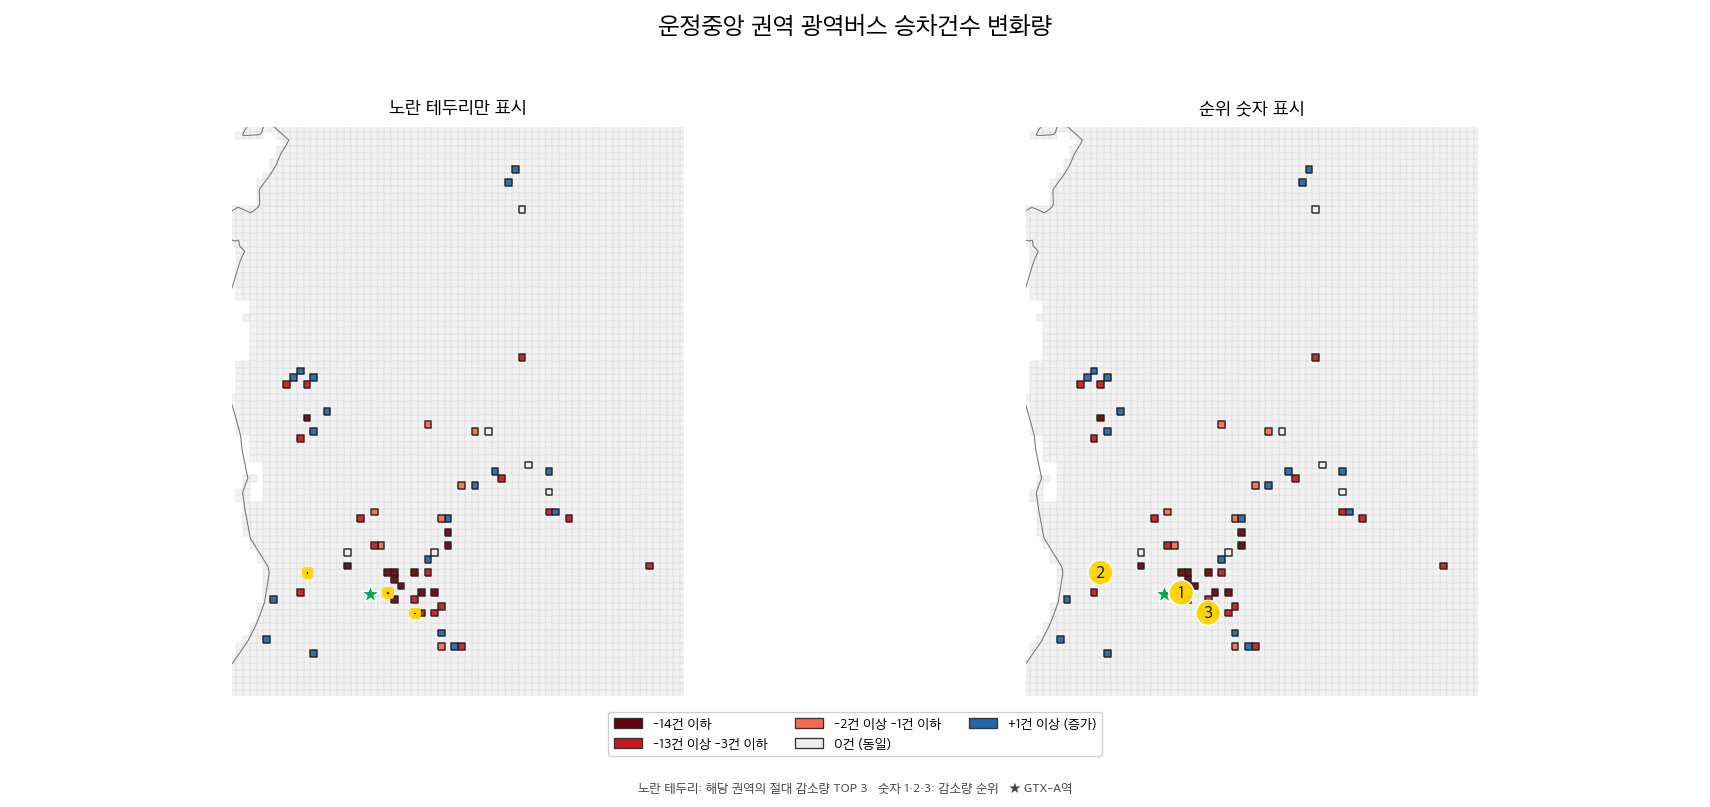

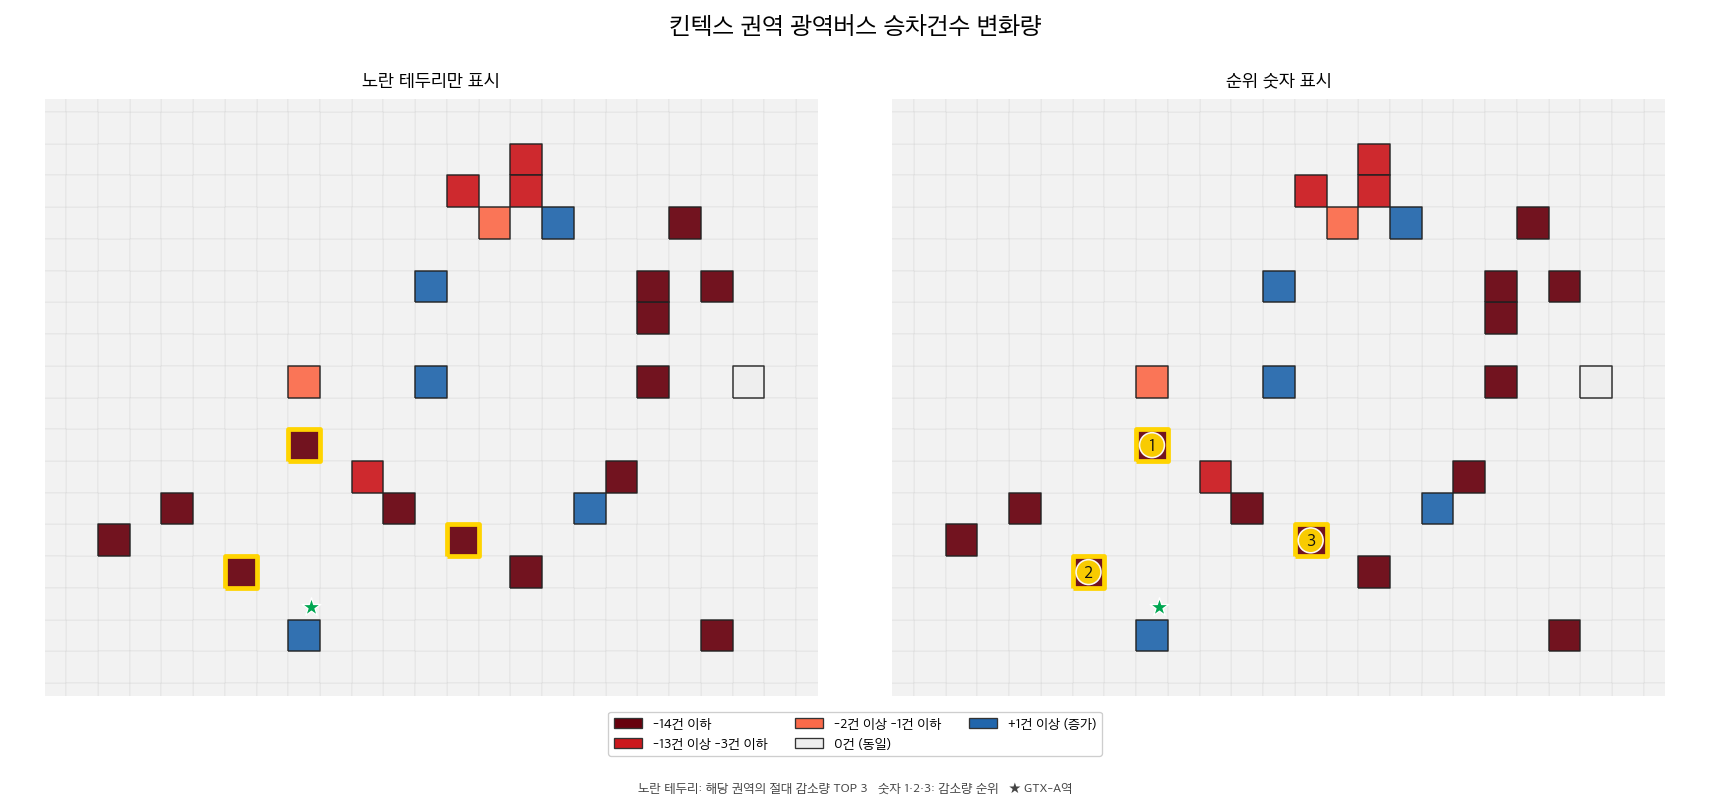

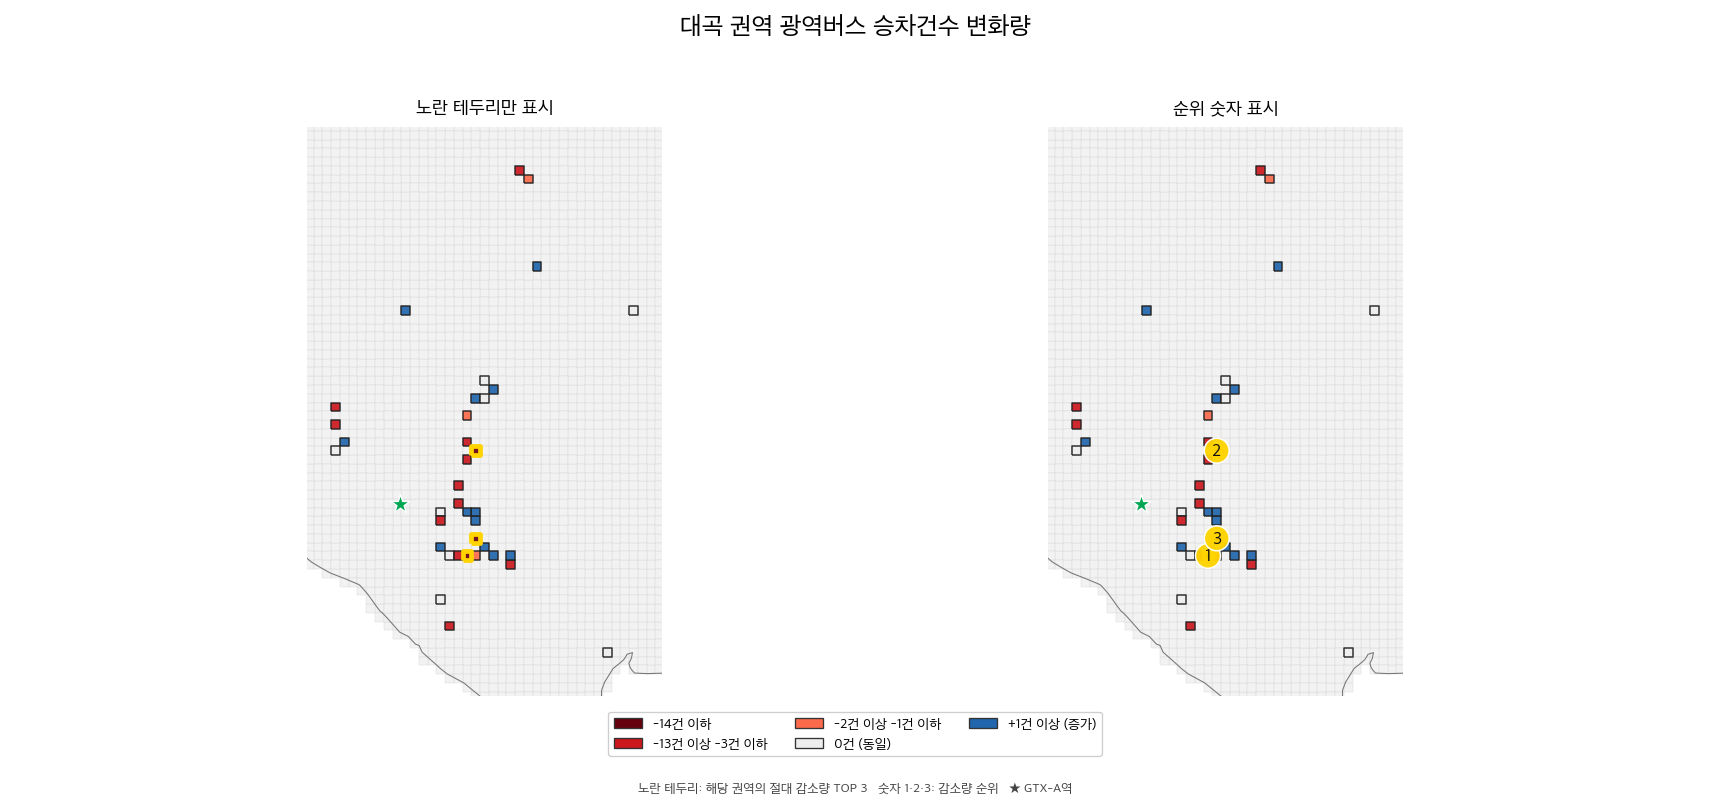

권역,감소 순위,셀 ID,중심점 위도,중심점 경도,2024년 승차건수,2025년 승차건수,변화량,지도 검색용 좌표
운정중앙,1,5217,37.716988,126.735542,265,137,-128,"37.716988, 126.735542"
운정중앙,2,13315,37.723522,126.701433,200,122,-78,"37.723522, 126.701433"
운정중앙,3,10778,37.710302,126.746956,436,374,-62,"37.710302, 126.746956"
킨텍스,1,4934,37.676505,126.747297,811,600,-211,"37.676505, 126.747297"
킨텍스,2,8868,37.667456,126.741720,424,262,-162,"37.667456, 126.741720"
킨텍스,3,10274,37.669835,126.761539,418,260,-158,"37.669835, 126.761539"
대곡,1,2477,37.618433,126.832867,50,34,-16,"37.618433, 126.832867"
대곡,2,2718,37.645488,126.835459,41,26,-15,"37.645488, 126.835459"
대곡,3,13997,37.622956,126.835660,31,17,-14,"37.622956, 126.835660"


In [ ]:
# 역 권역별 승차건수 변화량 확대 지도: 권역별 2개 패널, 126개 공통 경계
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, TwoSlopeNorm
from matplotlib.patches import Patch

# 뒤의 기존 변화율 애니메이션 셀에서 사용하는 정규화 유지
limit = max(1, float(plot_grid['변화율(%)'].abs().quantile(0.95)))
norm = TwoSlopeNorm(vmin=-limit, vcenter=0, vmax=limit)

# 건수 기준 입력을 셀 ID로 연결한다. 기존 plot_grid는 변경하지 않는다.
from pathlib import Path
import math
count_static_root = next(p for p in [Path.cwd(), *Path.cwd().parents]
                         if (p / 'config.py').is_file() and (p / 'code').is_dir())
count_static_data = pd.read_csv(
    count_static_root / 'data/final/gtx_a/S1_126격자_건수기준_기초표.csv', encoding='utf-8-sig'
)
assert len(count_static_data) == 126 and count_static_data['셀 ID'].is_unique
assert set(plot_grid['셀 ID'].astype(int)) == set(count_static_data['셀 ID'].astype(int))
count_plot_grid = plot_grid[['셀 ID', 'geometry']].merge(count_static_data, on='셀 ID', validate='one_to_one')
assert count_plot_grid[['board_2024', 'board_2025', 'change']].notna().all().all()
np.testing.assert_array_equal(count_plot_grid['change'], count_plot_grid.board_2025-count_plot_grid.board_2024)

# 126개 공통 사분위 경계. 증가=파랑, 동일=회색으로 별도 표시한다.
count_static_edges = count_plot_grid['change'].quantile([.25, .50, .75]).to_numpy()
quartile_colors = ['#67000D', '#CB181D', '#FB6A4A', '#FEE0D2']
count_plot_grid['변화량 사분위 코드'] = np.searchsorted(count_static_edges, count_plot_grid['change'], side='left')
count_plot_grid['건수 지도색'] = [
    '#2166AC' if value > 0 else '#EEEEEE' if value == 0 else quartile_colors[int(code)]
    for value, code in zip(count_plot_grid['change'], count_plot_grid['변화량 사분위 코드'])
]
quartile_handles = []
count_static_bins = []
for index, color in enumerate(quartile_colors):
    lower = None if index == 0 else math.floor(count_static_edges[index-1])+1
    upper = min(math.floor(count_static_edges[index]), -1) if index < 3 else -1
    if lower is not None and lower > upper:
        continue
    label = (f'{upper:,}건 이하' if lower is None else
             f'{lower:,}건' if lower == upper else f'{lower:,}건 이상 {upper:,}건 이하')
    quartile_handles.append(Patch(facecolor=color, edgecolor='#333333', label=label))
    mask = count_plot_grid['change'].le(upper)
    if lower is not None: mask &= count_plot_grid['change'].ge(lower)
    count_static_bins.append({'변화량 범위': label, '격자 수': int(mask.sum())})
for value, color, label in [(0, '#EEEEEE', '0건 (동일)'), (1, '#2166AC', '+1건 이상 (증가)')]:
    quartile_handles.append(Patch(facecolor=color, edgecolor='#333333', label=label))
    mask = count_plot_grid['change'].eq(0) if value == 0 else count_plot_grid['change'].gt(0)
    count_static_bins.append({'변화량 범위': label, '격자 수': int(mask.sum())})
print('건수 기준 변화량 공통 사분위 경계:', tuple(count_static_edges), '건')
display(pd.DataFrame(count_static_bins))

station_order = ['운정중앙', '킨텍스', '대곡']
panel_titles = {'운정중앙': '운정중앙 권역', '킨텍스': '킨텍스 권역', '대곡': '대곡 권역'}

def draw_region_map(ax, region, top3_region, station_name, bounds, show_rank=False):
    xmin, ymin, xmax, ymax = bounds

    # 기존 확대지도 형식: 주변 전체 격자는 연한 회색, 분석격자만 변화량 색상
    background = grid.cx[xmin:xmax, ymin:ymax]
    background.plot(
        ax=ax, facecolor='#F2F2F2', edgecolor='#D2D2D2',
        linewidth=0.28, zorder=1,
    )
    region.plot(
        ax=ax, color=region['건수 지도색'], edgecolor='#222222',
        linewidth=1.15, alpha=0.92, zorder=3,
    )

    # 권역별 절대 감소량 TOP 3는 노란 테두리로 강조
    if len(top3_region):
        top3_region.boundary.plot(
            ax=ax, color='#FFD400', linewidth=3.6, zorder=6,
        )

    # 숫자 표시 버전에는 TOP 1~3을 각각 1·2·3으로만 표시
    if show_rank:
        for _, row in top3_region.iterrows():
            point = row.geometry.representative_point()
            ax.text(
                point.x, point.y, str(int(row['감소 순위'])),
                ha='center', va='center', fontsize=13, fontweight='bold',
                color='#111111', zorder=8,
                bbox=dict(
                    boxstyle='circle,pad=0.26', facecolor='#FFD400',
                    edgecolor='white', linewidth=1.2, alpha=0.96,
                ),
            )

    station_point = stations[
        stations['역명'].str.replace('역', '', regex=False) == station_name
    ]
    station_point.plot(
        ax=ax, color='#00A651', marker='*', markersize=220,
        edgecolor='white', linewidth=1.0, zorder=7,
    )
    boundary_gdf.boundary.plot(ax=ax, color='#777777', linewidth=0.8, zorder=2)

    ax.set_xlim(xmin, xmax)
    ax.set_ylim(ymin, ymax)
    ax.set_aspect('equal')
    ax.set_title(
        '순위 숫자 표시' if show_rank else '노란 테두리만 표시',
        fontsize=14, fontweight='bold', pad=10,
    )
    ax.set_axis_off()


for station_name in station_order:
    region = count_plot_grid[count_plot_grid['nearest_station'].astype(str) == station_name].copy()
    top3_region = region[region['change'] < 0].nsmallest(3, 'change').copy().reset_index(drop=True)
    top3_region['감소 순위'] = np.arange(1, len(top3_region) + 1)

    xmin, ymin, xmax, ymax = region.total_bounds
    pad_x = max((xmax - xmin) * 0.08, 350)
    pad_y = max((ymax - ymin) * 0.08, 350)
    bounds = (xmin-pad_x, ymin-pad_y, xmax+pad_x, ymax+pad_y)

    # 권역마다 동일한 범위의 지도 2개: 테두리 전용 / 숫자 표시
    fig, axes = plt.subplots(1, 2, figsize=(18, 8.5))
    draw_region_map(axes[0], region, top3_region, station_name, bounds, show_rank=False)
    draw_region_map(axes[1], region, top3_region, station_name, bounds, show_rank=True)

    fig.suptitle(
        f'{panel_titles[station_name]} 광역버스 승차건수 변화량',
        fontsize=19, fontweight='bold', y=0.98,
    )
    fig.legend(
        handles=quartile_handles, loc='lower center', ncol=3,
        frameon=True, framealpha=0.96, bbox_to_anchor=(0.5, 0.055), fontsize=10.5,
    )
    fig.text(
        0.5, 0.018,
        '노란 테두리: 해당 권역의 절대 감소량 TOP 3   숫자 1·2·3: 감소량 순위   ★ GTX-A역',
        ha='center', fontsize=10, color='#444444',
    )
    plt.tight_layout(rect=[0, 0.12, 1, 0.94])
    plt.show()

# 권역별 절대 감소량 TOP 3 중심좌표: 지도 검색창에는 "위도, 경도"를 그대로 입력
top3_rows = []
for station_name in station_order:
    part = (
        count_plot_grid[(count_plot_grid['nearest_station'].astype(str) == station_name) & (count_plot_grid['change'] < 0)]
        .nsmallest(3, 'change')
        .copy()
        .reset_index(drop=True)
    )
    part['감소 순위'] = np.arange(1, len(part) + 1)
    top3_rows.append(part)

top3_coordinates = pd.concat(top3_rows, ignore_index=True)[
    ['nearest_station', '감소 순위', '셀 ID', '중심점 위도', '중심점 경도',
     'board_2024', 'board_2025', 'change']
].copy()
top3_coordinates['지도 검색용 좌표'] = (
    top3_coordinates['중심점 위도'].map(lambda x: f'{x:.6f}') + ', ' +
    top3_coordinates['중심점 경도'].map(lambda x: f'{x:.6f}')
)
top3_coordinates = top3_coordinates.rename(columns={
    'nearest_station': '권역',
    'board_2024': '2024년 승차건수',
    'board_2025': '2025년 승차건수',
    'change': '변화량',
})
print('권역별 절대 감소량 TOP 3 좌표(총 9개)')
display(top3_coordinates.round({
    '중심점 위도': 6, '중심점 경도': 6,
    '2024년 승차건수': 0, '2025년 승차건수': 0, '변화량': 0,
}))

### 카카오맵 위 250m 격자 오버레이

위의 기존 확대 지도는 그대로 유지한다. 아래 지도는 **같은 126개 격자의 실제 경계**를 카카오맵에 중첩한다. 색상은 전체 격자 공통 변화량 4분위수이며, 권역별 절대 감소량 TOP 3에만 노란 테두리를 표시한다. 격자를 클릭하면 해당 격자의 2024·2025년 승차인원과 변화량을 확인할 수 있다.

실행 전 [카카오디벨로퍼스](https://developers.kakao.com/docs/ko/kakaomap/common)에서 **카카오맵 API 사용 설정**을 켜고, JavaScript 키의 **JavaScript SDK 도메인**에 `http://localhost:8765`를 등록한다. 키는 아래 셀에서 숨김 입력하거나 `KAKAO_JAVASCRIPT_KEY` 환경변수로 전달한다. REST API 키는 사용할 수 없다. 지도는 인터넷에 연결된 노트북 브라우저에서 표시되며, 키나 HTML 파일은 디스크에 저장하지 않는다.


In [3]:
# 카카오맵: 126개 격자의 승차건수 변화량 (기존 정적 지도 데이터는 유지)
import numpy as np
import pandas as pd
import getpass
import os
import sys
from pathlib import Path

# 이 셀만 실행해도 현재 작업 폴더의 상위에서 프로젝트를 찾는다.
count_root_candidates = [Path.cwd(), *Path.cwd().parents]
UROP_ROOT = next((p for p in count_root_candidates
                  if (p / 'config.py').is_file() and (p / 'code').is_dir()), None)
if UROP_ROOT is None:
    raise FileNotFoundError('UROP 폴더 또는 그 하위 폴더를 작업 디렉터리로 열어 주세요.')

# 이전 커널에 남은 모듈과 지도 서버를 정리하고, 이 파일의 최신 코드를 직접 읽는다.
import types
count_overlay_path = UROP_ROOT / 'code/03_eda/kakao_grid_overlay.py'
count_old_module = sys.modules.get('kakao_grid_overlay')
if count_old_module is not None and getattr(count_old_module, '_server', None) is not None:
    count_old_module._server.shutdown()
    count_old_module._server.server_close()
    if getattr(count_old_module, '_thread', None) is not None:
        count_old_module._thread.join(timeout=5)
count_overlay_module = types.ModuleType('kakao_grid_overlay')
count_overlay_module.__file__ = str(count_overlay_path)
exec(compile(count_overlay_path.read_text(encoding='utf-8'), str(count_overlay_path), 'exec'),
     count_overlay_module.__dict__)
sys.modules['kakao_grid_overlay'] = count_overlay_module
show_kakao_overlay = count_overlay_module.show_kakao_overlay

# S1 건수 자료를 셀 ID로 연결한다. 기존 plot_grid의 이용인원 값은 변경하지 않는다.
count_map_data = pd.read_csv(
    UROP_ROOT / 'data/final/gtx_a/S1_126격자_건수기준_기초표.csv',
    encoding='utf-8-sig',
)
assert len(count_map_data) == 126 and count_map_data['셀 ID'].is_unique
# 앞선 지도 셀 실행 여부와 관계없이 동일한 원본 격자 생성 순서를 사용한다.
import geopandas as gpd
count_admin_path = UROP_ROOT / 'data/raw/common/api_cache_gtx_a_routes/HangJeongDong_ver20260701.geojson'
count_grid_path = next((UROP_ROOT / 'data/raw/common/grid/빈격자(250m)').glob('*.shp'))
count_grid_crs = gpd.read_file(count_grid_path, rows=1).crs
count_admin = gpd.read_file(count_admin_path).to_crs(count_grid_crs)
count_admin['sgg_code'] = count_admin['sgg'].astype(str).str.extract(r'([0-9]+)')[0].str.zfill(5)
count_city = count_admin[count_admin['sgg_code'].str.startswith(('4128', '4148'))]
count_boundary = count_city.geometry.union_all() if hasattr(count_city.geometry, 'union_all') else count_city.geometry.unary_union
count_geometry = gpd.read_file(count_grid_path, bbox=count_boundary.bounds)
count_geometry = count_geometry[count_geometry.geometry.intersects(count_boundary)].copy()
count_geometry['_key'] = count_geometry.geometry.apply(lambda g: g.wkb if g is not None else None)
count_geometry = count_geometry.drop_duplicates('_key').drop(columns='_key').reset_index(drop=True)
count_geometry['셀 ID'] = np.arange(1, len(count_geometry) + 1)
count_map_grid = count_geometry[['셀 ID', 'geometry']].merge(
    count_map_data[['셀 ID', 'nearest_station', 'board_2024', 'board_2025', 'change']],
    on='셀 ID', how='inner', validate='one_to_one',
)
assert len(count_map_grid) == 126 and count_map_grid['셀 ID'].is_unique
assert count_map_grid[['board_2024', 'board_2025', 'change']].notna().all().all()
np.testing.assert_array_equal(
    count_map_grid['change'], count_map_grid['board_2025'] - count_map_grid['board_2024']
)
count_map_edges = tuple(count_map_grid['change'].quantile([.25, .50, .75]))
# 전체 126개 공통 사분위: 경계값은 낮은 구간에 포함한다.
count_map_grid['변화량 사분위 코드'] = np.searchsorted(
    count_map_edges, count_map_grid['change'].to_numpy(), side='left'
)
print('건수 기준 변화량 사분위 경계:', count_map_edges, '건')
print('지도 색상: 증가=파랑 / 동일=회색 / 감소=빨강 계열')
print('감소:', int(count_map_grid['change'].lt(0).sum()),
      '동일:', int(count_map_grid['change'].eq(0).sum()),
      '증가:', int(count_map_grid['change'].gt(0).sum()))

kakao_js_key = os.getenv('KAKAO_JAVASCRIPT_KEY', '').strip() or getpass.getpass('카카오 JavaScript 키: ').strip()
station_coords = {
    '운정중앙': (37.716670, 126.728330),
    '킨텍스': (37.665000, 126.748060),
    '대곡': (37.631626, 126.811024),
}
show_kakao_overlay(
    plot_grid=count_map_grid,
    station_coords=station_coords,
    quartile_edges=count_map_edges,
    app_key=kakao_js_key,
    count_basis=True,
)
del kakao_js_key  # 노트북 변수에 키가 오래 남지 않도록 제거


건수 기준 변화량 사분위 경계: (-13.75, -3.0, 1.0) 건
지도 색상: 증가=파랑 / 동일=회색 / 감소=빨강 계열
감소: 76 동일: 15 증가: 35


격자 126개 오버레이 준비 완료. 지도가 비어 있으면 카카오 JavaScript 키와 등록 도메인(http://localhost:8765)을 확인하세요.


### 권역별 승차건수 변화량
동일한 126개 분석격자의 승차건수를 권역별로 합산하여 2025년 − 2024년 변화량을 비교한다.


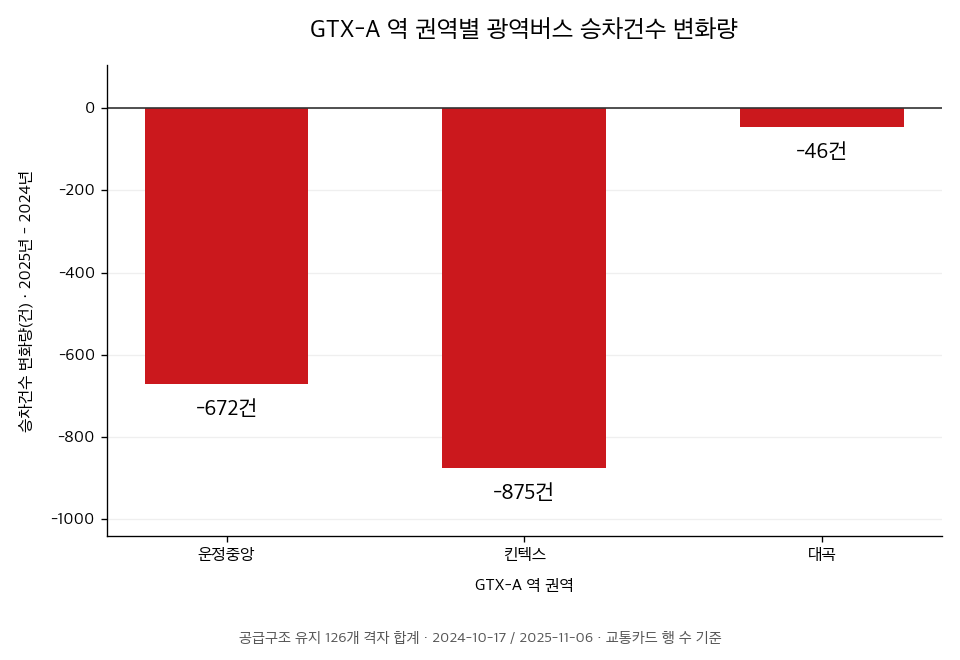

In [ ]:
# 권역별 승차건수 변화량 합계 — 단독 실행 가능, 그림 파일 저장 없음
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm

region_bar_root = next(p for p in [Path.cwd(), *Path.cwd().parents]
                       if (p / 'config.py').is_file() and (p / 'code').is_dir())
region_bar_data = pd.read_csv(
    region_bar_root / 'data/final/gtx_a/S1_126격자_건수기준_기초표.csv', encoding='utf-8-sig'
)
assert len(region_bar_data) == 126 and region_bar_data['셀 ID'].is_unique
region_bar_order = ['운정중앙', '킨텍스', '대곡']
region_bar_summary = region_bar_data.groupby('nearest_station')[['board_2024', 'board_2025']].sum().reindex(region_bar_order)
assert region_bar_summary.notna().all().all()
region_bar_summary['변화량(건)'] = region_bar_summary['board_2025'] - region_bar_summary['board_2024']
for region_bar_font in [Path('/System/Library/Fonts/AppleSDGothicNeo.ttc'),
                        Path(r'C:\Windows\Fonts\malgun.ttf'), Path('/Library/Fonts/NanumGothic.ttf')]:
    if region_bar_font.is_file():
        fm.fontManager.addfont(str(region_bar_font))
        plt.rcParams['font.family'] = fm.FontProperties(fname=str(region_bar_font)).get_name()
        break
plt.rcParams['axes.unicode_minus'] = False

fig, ax = plt.subplots(figsize=(8, 5.5))
region_bar_values = region_bar_summary['변화량(건)']
ax.bar(region_bar_order, region_bar_values,
       color=['#2166AC' if v > 0 else '#CB181D' if v < 0 else '#AAAAAA' for v in region_bar_values], width=.55)
ax.axhline(0, color='#333333', linewidth=1)
region_bar_span = max(1, float(region_bar_values.abs().max()))
ax.set_ylim(min(0, float(region_bar_values.min())) - region_bar_span * .19,
            max(0, float(region_bar_values.max())) + region_bar_span * .12)
for region_bar_index, region_bar_value in enumerate(region_bar_values):
    ax.annotate(f'{int(region_bar_value):+,}건', (region_bar_index, region_bar_value),
                xytext=(0, -9 if region_bar_value < 0 else 7), textcoords='offset points',
                ha='center', va='top' if region_bar_value < 0 else 'bottom', fontsize=13, fontweight='bold')
ax.set_title('GTX-A 역 권역별 광역버스 승차건수 변화량', fontsize=15, pad=16)
ax.set_xlabel('GTX-A 역 권역', labelpad=10)
ax.set_ylabel('승차건수 변화량(건) · 2025년 - 2024년', labelpad=10)
ax.spines[['top', 'right']].set_visible(False)
ax.grid(axis='y', alpha=.2)
ax.set_axisbelow(True)
fig.text(.5, .025, '공급구조 유지 126개 격자 합계 · 2024-10-17 / 2025-11-06 · 교통카드 행 수 기준',
         ha='center', fontsize=9, color='#555555')
fig.tight_layout(rect=[0, .07, 1, 1])
plt.show()


### 권역별 승차인원 변화량 — 기존 이용인원 합계 기준(비교용)
동일한 126개 격자를 utztn_nope 합계로 집계한 기존 방식이다. 날짜 간 이용인원 생성 방식이 달라 주 분석은 위의 승차건수 기준을 사용한다.


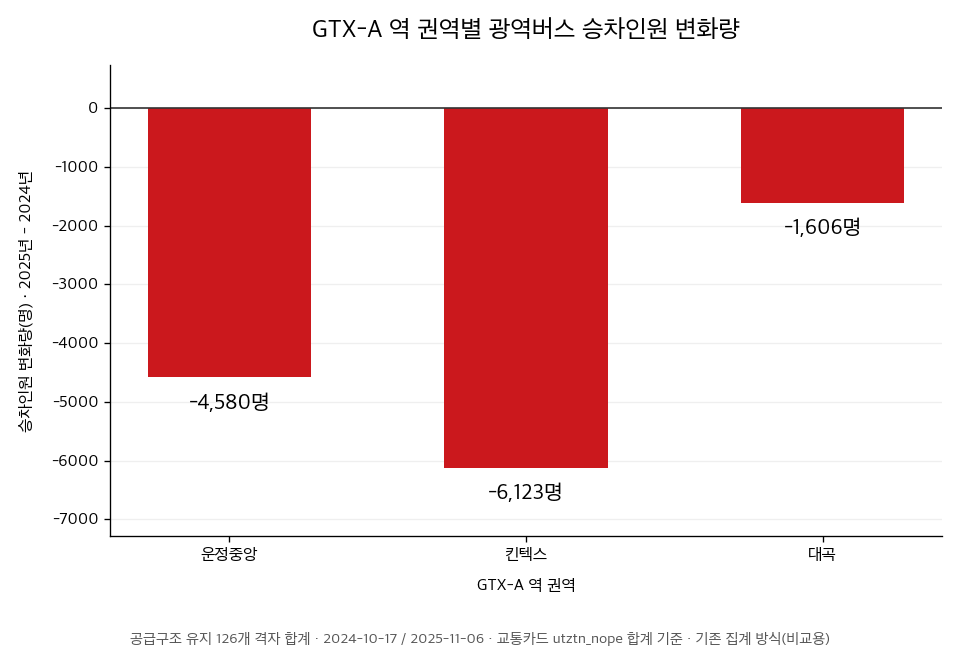

In [ ]:
# 권역별 승차인원 변화량 합계 — 이용인원 기준 비교용, 그림 파일 저장 없음
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm

person_bar_root = next(p for p in [Path.cwd(), *Path.cwd().parents]
                       if (p / 'config.py').is_file() and (p / 'code').is_dir())
person_bar_data = pd.read_csv(
    person_bar_root / 'data/final/gtx_a/S1_126격자_건수기준_기초표.csv', encoding='utf-8-sig'
)
assert len(person_bar_data) == 126 and person_bar_data['셀 ID'].is_unique
person_bar_order = ['운정중앙', '킨텍스', '대곡']
person_bar_summary = person_bar_data.groupby('nearest_station')[['[이용인원]board_2024_all', '[이용인원]board_2025_all']].sum().reindex(person_bar_order)
assert person_bar_summary.notna().all().all()
person_bar_summary['변화량(명)'] = person_bar_summary['[이용인원]board_2025_all'] - person_bar_summary['[이용인원]board_2024_all']
for person_bar_font in [Path('/System/Library/Fonts/AppleSDGothicNeo.ttc'),
                        Path(r'C:\Windows\Fonts\malgun.ttf'), Path('/Library/Fonts/NanumGothic.ttf')]:
    if person_bar_font.is_file():
        fm.fontManager.addfont(str(person_bar_font))
        plt.rcParams['font.family'] = fm.FontProperties(fname=str(person_bar_font)).get_name()
        break
plt.rcParams['axes.unicode_minus'] = False

fig, ax = plt.subplots(figsize=(8, 5.5))
person_bar_values = person_bar_summary['변화량(명)']
ax.bar(person_bar_order, person_bar_values,
       color=['#2166AC' if v > 0 else '#CB181D' if v < 0 else '#AAAAAA' for v in person_bar_values], width=.55)
ax.axhline(0, color='#333333', linewidth=1)
person_bar_span = max(1, float(person_bar_values.abs().max()))
ax.set_ylim(min(0, float(person_bar_values.min())) - person_bar_span * .19,
            max(0, float(person_bar_values.max())) + person_bar_span * .12)
for person_bar_index, person_bar_value in enumerate(person_bar_values):
    ax.annotate(f'{int(person_bar_value):+,}명', (person_bar_index, person_bar_value),
                xytext=(0, -9 if person_bar_value < 0 else 7), textcoords='offset points',
                ha='center', va='top' if person_bar_value < 0 else 'bottom', fontsize=13, fontweight='bold')
ax.set_title('GTX-A 역 권역별 광역버스 승차인원 변화량', fontsize=15, pad=16)
ax.set_xlabel('GTX-A 역 권역', labelpad=10)
ax.set_ylabel('승차인원 변화량(명) · 2025년 - 2024년', labelpad=10)
ax.spines[['top', 'right']].set_visible(False)
ax.grid(axis='y', alpha=.2)
ax.set_axisbelow(True)
fig.text(.5, .025, '공급구조 유지 126개 격자 합계 · 2024-10-17 / 2025-11-06 · 교통카드 utztn_nope 합계 기준 · 기존 집계 방식(비교용)',
         ha='center', fontsize=9, color='#555555')
fig.tight_layout(rect=[0, .07, 1, 1])
plt.show()


## 2. 2024년에서 2025년으로의 승차 변화 애니메이션녹색 테두리는 GTX-A역이 포함된 격자이다.

저장: /Users/keumkyounghoon/Desktop/Gachon/3-2/UROP/github_2026-UROP/gtx_a_bus_analysis/outputs/figures_011/03_확대_2024_2025_승차변화.gif


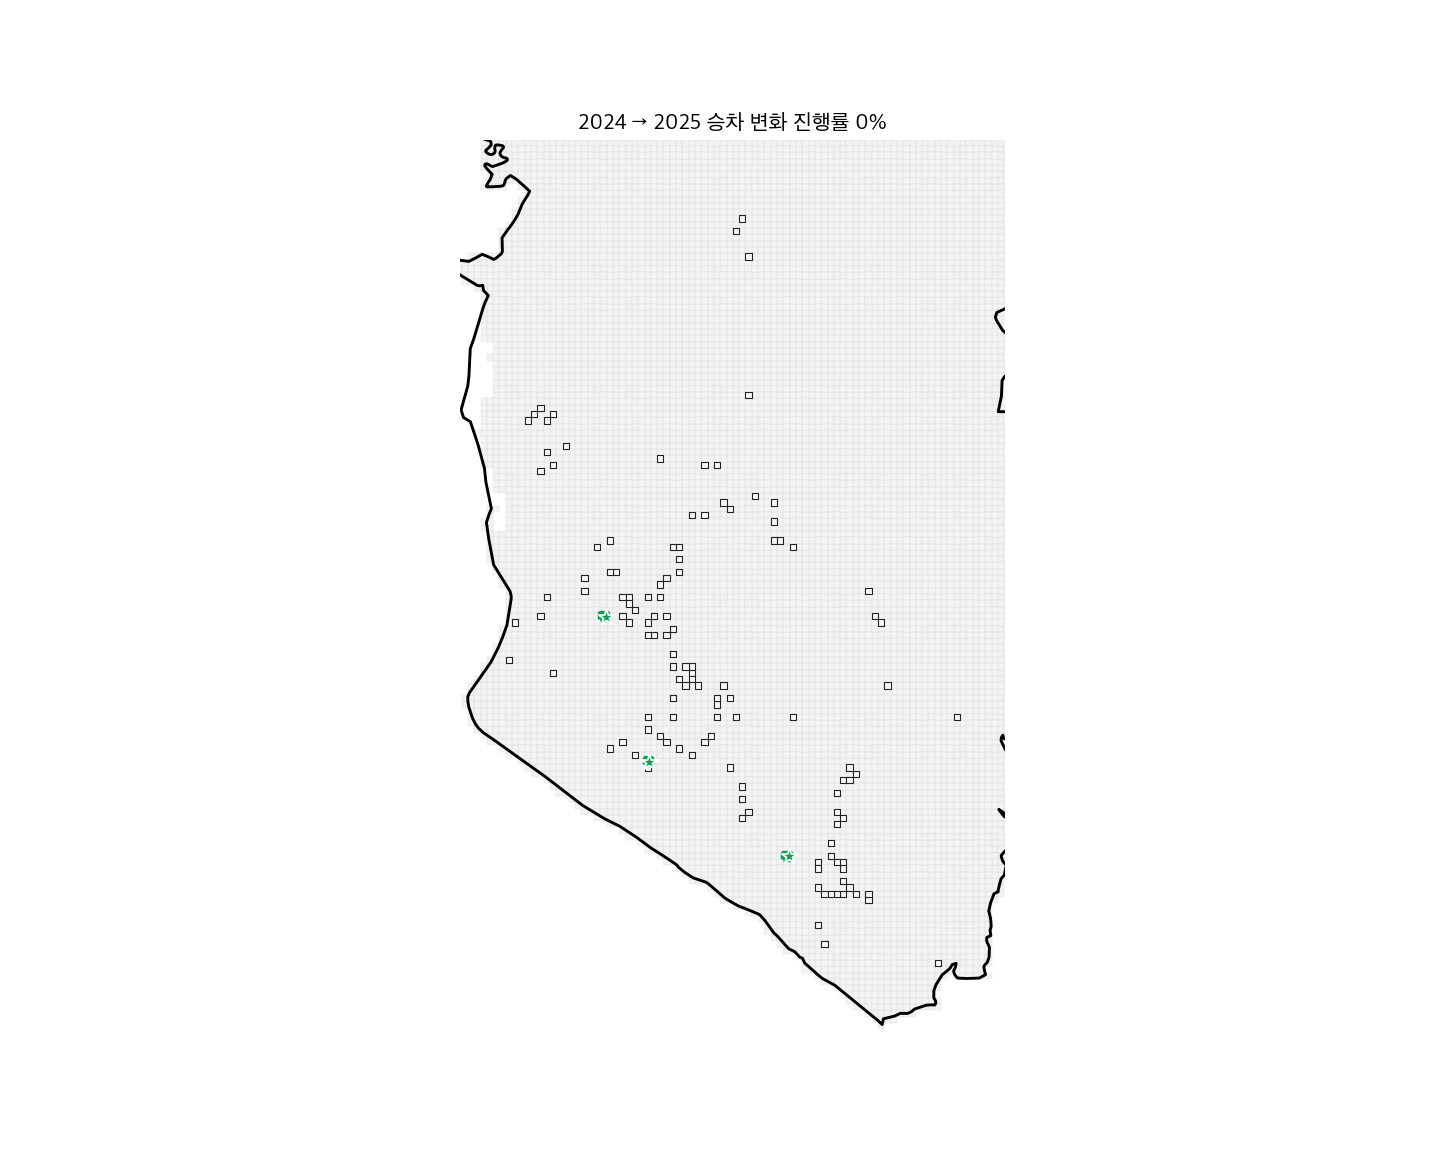

In [16]:
gif_path = FIGURES / '03_확대_2024_2025_승차변화.gif'
fig, ax = plt.subplots(figsize=(11, 9))
frames = np.linspace(0, 1, 25)
def update(progress):
    ax.clear()
    grid.plot(ax=ax, facecolor='#F3F3F3', edgecolor='#D3D3D3', linewidth=0.15, zorder=1)
    animated = plot_grid.copy(); animated['진행 변화율(%)'] = animated['변화율(%)'] * progress
    animated.plot(ax=ax, column='진행 변화율(%)', cmap='RdBu_r', norm=norm, edgecolor='#222222', linewidth=0.6, zorder=2)
    station_cells.boundary.plot(ax=ax, color='#00A651', linewidth=3.0, zorder=4)
    stations.plot(ax=ax, color='#00A651', marker='*', markersize=80, edgecolor='white', zorder=5)
    boundary_gdf.boundary.plot(ax=ax, color='black', linewidth=1.6, zorder=6)
    xmin, ymin, xmax, ymax = plot_grid.total_bounds; padx, pady = (xmax-xmin)*0.10, (ymax-ymin)*0.10
    ax.set_xlim(xmin-padx, xmax+padx); ax.set_ylim(ymin-pady, ymax+pady)
    ax.set_title(f'2024 → 2025 승차 변화 진행률 {progress*100:.0f}%')
    ax.set_axis_off()
anim = FuncAnimation(fig, update, frames=frames, interval=140, repeat=True)
anim.save(gif_path, writer=PillowWriter(fps=7), dpi=130)
plt.close(fig)
print('저장:', gif_path)
display(Image(filename=str(gif_path)))

## 3. 250m 격자별 GTX-A역과의 거리구간별 승차인원 변화

최근접 GTX-A역과 격자 중심점 사이의 직선거리를 비누적 구간으로 구분한다. 따라서 각 격자는 하나의 거리구간에만 포함된다.


In [17]:
# 250m 격자별 GTX-A역과의 비누적 거리구간별 승차인원 변화
# 이 셀은 앞 셀 실행 여부와 관계없이 단독으로 실행할 수 있다.
from pathlib import Path
import geopandas as gpd
import numpy as np
import pandas as pd
from IPython.display import display

PROJECT_DISTANCE = UROP_ROOT
PROCESSED_DISTANCE = PROJECT_DISTANCE / 'data' / 'processed' / 'gtx_a'
FIGURES_DISTANCE = PROJECT_DISTANCE / 'results' / 'eda' / 'figures_011'
FIGURES_DISTANCE.mkdir(parents=True, exist_ok=True)

MODEL_DISTANCE_PATH = next(PROCESSED_DISTANCE.glob('18_*.csv'))
distance_model = pd.read_csv(MODEL_DISTANCE_PATH, encoding='utf-8-sig')
distance_model['셀 ID'] = pd.to_numeric(distance_model['셀 ID'], errors='coerce').astype('Int64')

# 격자 중심점과 GTX-A 3개 역을 EPSG:5179로 투영한 뒤 km 단위 직선거리를 계산한다.
distance_cells = gpd.GeoDataFrame(
    distance_model.copy(),
    geometry=gpd.points_from_xy(
        distance_model['중심점 경도'], distance_model['중심점 위도']
    ),
    crs='EPSG:4326',
).to_crs('EPSG:5179')

distance_stations = gpd.GeoDataFrame(
    {'GTX-A역': ['운정중앙역', '킨텍스역', '대곡역']},
    geometry=gpd.points_from_xy(
        [126.728330, 126.748060, 126.811024],
        [37.716670, 37.665000, 37.631626],
    ),
    crs='EPSG:4326',
).to_crs('EPSG:5179')

distance_matrix = np.column_stack([
    distance_cells.geometry.distance(station_geometry) / 1000
    for station_geometry in distance_stations.geometry
])
distance_cells['최근접 GTX-A역'] = np.asarray(distance_stations['GTX-A역'])[
    distance_matrix.argmin(axis=1)
]
distance_cells['최근접역 거리(km)'] = distance_matrix.min(axis=1)

# 0~1km부터 4~5km까지는 1km 간격이며, 5km 이상은 하나로 묶는다.
distance_bins = [0, 1, 2, 3, 4, 5, np.inf]
distance_labels = ['0~1km', '1~2km', '2~3km', '3~4km', '4~5km', '5km 이상']
distance_cells['GTX-A역 거리구간'] = pd.cut(
    distance_cells['최근접역 거리(km)'],
    bins=distance_bins,
    labels=distance_labels,
    right=False,
    include_lowest=True,
)
distance_cells['감소 셀 여부'] = distance_cells['change_all'] < 0

distance_table = (
    distance_cells.groupby('GTX-A역 거리구간', observed=False)
    .agg(
        셀_수=('셀 ID', 'size'),
        **{
            '2024년 승차인원': ('board_2024_all', 'sum'),
            '2025년 승차인원': ('board_2025_all', 'sum'),
            '승차인원 변화량': ('change_all', 'sum'),
            '승차인원 변화 중앙값': ('change_all', 'median'),
            '감소 셀': ('감소 셀 여부', 'sum'),
        },
    )
    .reset_index()
    .rename(columns={'셀_수': '셀 수'})
)
distance_table['승차인원 변화율(%)'] = np.where(
    distance_table['2024년 승차인원'] > 0,
    distance_table['승차인원 변화량'] / distance_table['2024년 승차인원'] * 100,
    np.nan,
)
distance_table['감소 비율(%)'] = np.where(
    distance_table['셀 수'] > 0,
    distance_table['감소 셀'] / distance_table['셀 수'] * 100,
    np.nan,
)

distance_table = distance_table[[
    'GTX-A역 거리구간', '셀 수', '승차인원 변화 중앙값',
    '감소 셀', '감소 비율(%)'
]]

total_row = pd.DataFrame([{
    'GTX-A역 거리구간': '전체',
    '셀 수': len(distance_cells),
    '승차인원 변화 중앙값': distance_cells['change_all'].median(),
    '감소 셀': int(distance_cells['감소 셀 여부'].sum()),
    '감소 비율(%)': distance_cells['감소 셀 여부'].mean() * 100,
}])
distance_table_with_total = pd.concat([distance_table, total_row], ignore_index=True)

print('[250m 격자별 GTX-A역과의 거리구간별 승차인원 변화]')
display(distance_table_with_total.round(1))

distance_output = FIGURES_DISTANCE / '04_GTX-A역_거리구간별_승차인원변화_요약.csv'
distance_table_with_total.to_csv(distance_output, index=False, encoding='utf-8-sig')
print('저장:', distance_output)


 격자별 GTX-A역과의 거리구간별 승차인원 변화]
저장: /Users/keumkyounghoon/Desktop/Gachon/3-2/UROP/github_2026-UROP/gtx_a_bus_analysis/outputs/figures_011/04_GTX-A역_거리구간별_승차인원변화_요약.csv


,GTX-A역 거리구간,셀 수,승차인원 변화 중앙값,감소 셀,감소 비율(%)
0,0~1km,4,-495.5,4,100.0
1,1~2km,26,-76.5,26,100.0
2,2~3km,29,-54.0,27,93.1
3,3~4km,28,-34.5,28,100.0
4,4~5km,6,-11.5,4,66.7
5,5km 이상,33,-8.0,28,84.8
6,전체,126,-39.5,117,92.9


## 4. 전체 감소·유지·증가 셀 수

,구분,셀 수,비율(%)
0,감소,117,92.9
1,유지,5,4.0
2,증가,4,3.2


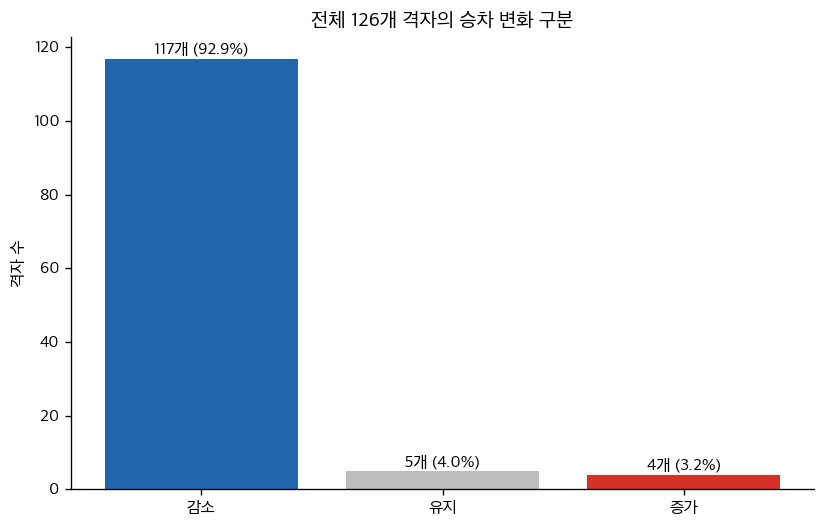

In [18]:
model['변화 구분'] = np.select([model['change_all'] < 0, model['change_all'] > 0], ['감소', '증가'], default='유지')
change_summary = model['변화 구분'].value_counts().reindex(['감소','유지','증가'], fill_value=0).rename_axis('구분').reset_index(name='셀 수')
change_summary['비율(%)'] = change_summary['셀 수'] / len(model) * 100
display(change_summary.round(1))
fig, ax = plt.subplots(figsize=(7, 4.5))
colors = {'감소':'#2166ac','유지':'#bdbdbd','증가':'#d73027'}
bars = ax.bar(change_summary['구분'], change_summary['셀 수'], color=[colors[x] for x in change_summary['구분']])
for bar, n, pct in zip(bars, change_summary['셀 수'], change_summary['비율(%)']): ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+1, f'{n}개 ({pct:.1f}%)', ha='center')
ax.set_ylabel('격자 수'); ax.set_title('전체 126개 격자의 승차 변화 구분'); ax.spines[['top','right']].set_visible(False)
plt.tight_layout(); fig.savefig(FIGURES / '05_감소_유지_증가_셀수.png', dpi=220, bbox_inches='tight'); plt.show()

## 5. 노선별 승차 변화율

공급구조가 유지된 126개 셀에 포함된 승차기록만 노선별로 합산한다. 노선 수가 많으므로 변화율 순서대로 절반씩 나누어 두 개의 그림으로 제시한다.


,노선,2024년 승차인원,2025년 승차인원,증감,변화율(%)
0,3400,879,175,-704,-80.1
1,M7154,369,75,-294,-79.7
2,9030-1,39,9,-30,-76.9
3,7101,554,137,-417,-75.3
4,G7625,622,156,-466,-74.9
5,1500,1189,309,-880,-74.0
6,3100,900,240,-660,-73.3
7,1000,3547,948,-2599,-73.3
8,9600,118,32,-86,-72.9
9,9710,220,60,-160,-72.7


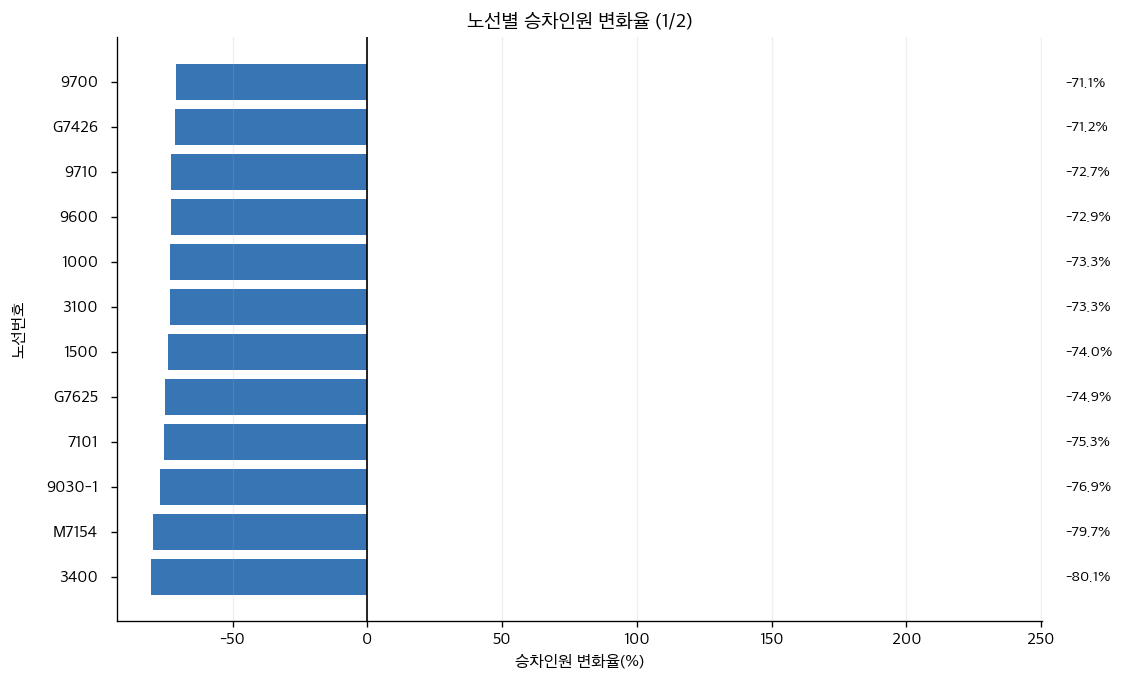

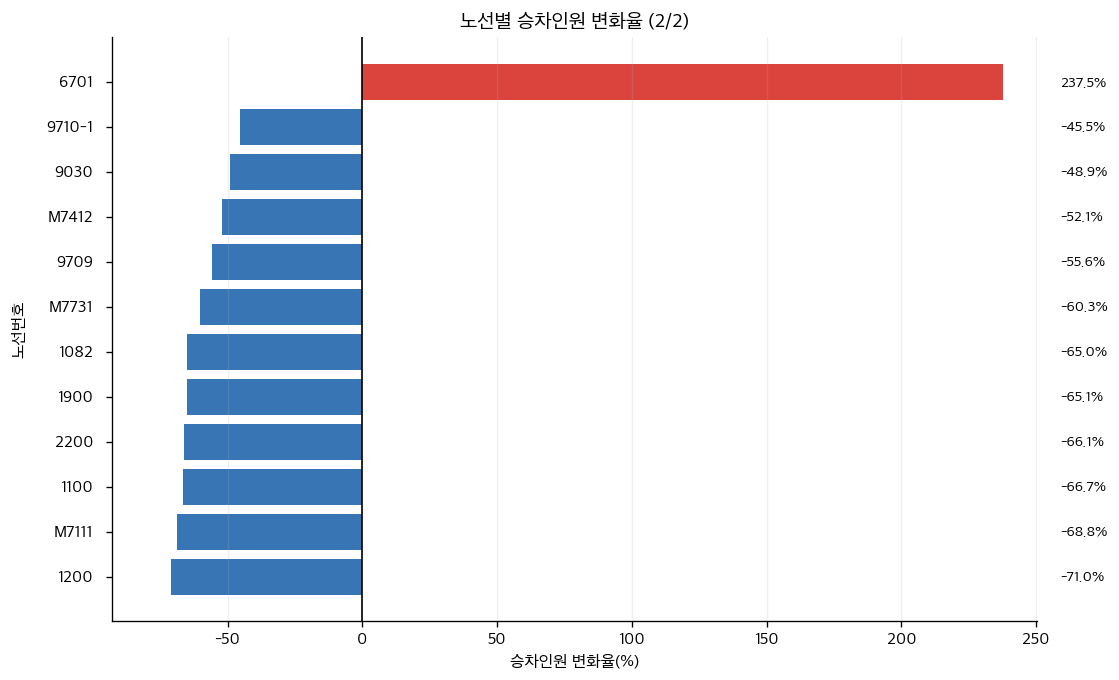

In [19]:
# 노선별 승차 변화율: 노선을 절반씩 나누어 두 개의 그림으로 출력
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
from IPython.display import display

PROJECT_ROUTE = UROP_ROOT
ROOT_ROUTE = UROP_ROOT
PROCESSED_ROUTE = PROJECT_ROUTE / 'data' / 'processed' / 'gtx_a'
FIGURES_ROUTE = PROJECT_ROUTE / 'results' / 'eda' / 'figures_011'
FIGURES_ROUTE.mkdir(parents=True, exist_ok=True)

STABLE_ROUTE_PATH = next(PROCESSED_ROUTE.glob('16_*.csv'))
CARD_DIR_ROUTE = ROOT_ROUTE / 'data' / 'raw' / 'gtx_a' / 'transport_card'
RAW24_ROUTE = CARD_DIR_ROUTE / 'gtx_a_transport_card_20241017_raw_with_coords_api_filled.csv'
RAW25_ROUTE = CARD_DIR_ROUTE / 'gtx_a_transport_card_20251106_raw_with_coords.csv'

font_path_route = Path(r'C:\Windows\Fonts\malgun.ttf')
if font_path_route.exists():
    fm.fontManager.addfont(str(font_path_route))
    plt.rcParams['font.family'] = fm.FontProperties(fname=str(font_path_route)).get_name()
plt.rcParams['axes.unicode_minus'] = False

stable_route = pd.read_csv(STABLE_ROUTE_PATH, encoding='utf-8-sig')
stable_route['셀 ID'] = pd.to_numeric(stable_route['셀 ID'], errors='coerce').astype('Int64')

def split_stop_ids(value):
    return [
        item.strip() for item in str(value).split('|')
        if item.strip() and item.strip().lower() != 'nan'
    ]

stop_to_cell = {}
for year, column in [(2024, '2024년 정류장 ID'), (2025, '2025년 정류장 ID')]:
    stop_to_cell[year] = {
        stop_id: int(row['셀 ID'])
        for _, row in stable_route.iterrows()
        for stop_id in split_stop_ids(row[column])
    }

def aggregate_route_boarding(raw_path, year):
    data = pd.read_csv(raw_path, encoding='utf-8-sig', low_memory=False)
    stop_id = data['ride_sttn_id'].astype(str).str.replace(r'\.0$', '', regex=True)
    data['셀 ID'] = stop_id.map(stop_to_cell[year])
    data['승차인원'] = pd.to_numeric(data['utztn_nope'], errors='coerce').fillna(0)
    data['노선'] = data['query_route_no'].astype(str).str.replace(r'\.0$', '', regex=True)
    return data[data['셀 ID'].notna()].groupby('노선')['승차인원'].sum()

route_2024 = aggregate_route_boarding(RAW24_ROUTE, 2024)
route_2025 = aggregate_route_boarding(RAW25_ROUTE, 2025)
route_change = pd.concat([
    route_2024.rename('2024년 승차인원'),
    route_2025.rename('2025년 승차인원'),
], axis=1).fillna(0).reset_index()
route_change['증감'] = route_change['2025년 승차인원'] - route_change['2024년 승차인원']
route_change['변화율(%)'] = np.where(
    route_change['2024년 승차인원'] > 0,
    route_change['증감'] / route_change['2024년 승차인원'] * 100,
    np.nan,
)
route_change = route_change.sort_values('변화율(%)').reset_index(drop=True)
display(route_change.round(1))
# 두 그림 모두 전체 노선의 최솟값·최댓값을 이용한 동일한 x축 범위를 사용한다.
finite_rate = route_change['변화율(%)'].replace([np.inf, -np.inf], np.nan).dropna()
x_padding = max(5.0, float(finite_rate.max() - finite_rate.min()) * 0.04)
shared_x_min = float(finite_rate.min()) - x_padding
shared_x_max = float(finite_rate.max()) + x_padding

midpoint = int(np.ceil(len(route_change) / 2))
route_parts = [route_change.iloc[:midpoint], route_change.iloc[midpoint:]]

for figure_number, route_part in enumerate(route_parts, start=1):
    fig_height = max(5.8, len(route_part) * 0.52)
    fig, ax = plt.subplots(figsize=(11.5, fig_height))
    colors = np.where(route_part['변화율(%)'] < 0, '#2166ac', '#d73027')
    ax.barh(route_part['노선'], route_part['변화율(%)'], color=colors, alpha=0.9)
    ax.axvline(0, color='black', linewidth=1)
    ax.set_xlim(shared_x_min, shared_x_max)
    ax.set_xlabel('승차인원 변화율(%)')
    ax.set_ylabel('노선번호', labelpad=12)
    ax.set_title(f'노선별 승차인원 변화율 ({figure_number}/2)')
    ax.spines[['top', 'right']].set_visible(False)
    ax.grid(axis='x', alpha=0.2)
    ax.tick_params(axis='y', pad=8, labelsize=10)

    # 변화율 수치는 막대 끝이 아닌 오른쪽 고정 열에 배치하여 노선번호와 겹치지 않게 한다.
    for y_position, value in enumerate(route_part['변화율(%)']):
        if pd.notna(value):
            ax.text(
                1.025, y_position, f'{value:.1f}%',
                transform=ax.get_yaxis_transform(),
                va='center', ha='left', fontsize=9, clip_on=False,
                bbox=dict(facecolor='white', edgecolor='none', alpha=0.78, pad=1.0),
            )

    # 오른쪽 여백은 변화율 숫자만 표시하는 별도 공간이다.
    fig.subplots_adjust(left=0.16, right=0.83, top=0.90, bottom=0.12)
    plt.show()


### 5-1. 노선별 승차 변화율 — 승차건수 기준

기존 이용인원 기준 결과는 위에 보존한다. 아래는 동일한 126개 공급구조 유지 격자 내부에서 교통카드 **행 수**로 다시 집계한 결과다. `utztn_nope`는 가중치로 사용하지 않는다.

비교일: 2024-10-17 / 2025-11-06. 노선 전체 구간 실적이 아닌 분석격자 내부 실적이다. 개통 전 0건이면 변화율은 산출하지 않으며, 20건 미만은 표에 표시만 하고 제외하지 않는다. 그래프 두 장은 동일한 가로축 범위를 사용한다.


126개 격자 · 24개 노선 | 2024-10-17: 7,110건 → 2025-11-06: 5,517건
전체 변화율: -22.41% | 격자별 S1 건수와 일치 확인


,노선,2024년 승차건수,2025년 승차건수,변화량(건),변화율(%),소규모 기초건수 주의
0,3400,361,173,-188,-52.08,
1,M7154,154,75,-79,-51.30,
2,9030-1,15,9,-6,-40.00,20건 미만
3,7101,217,137,-80,-36.87,
4,G7625,246,156,-90,-36.59,
5,1500,466,304,-162,-34.76,
6,9710,89,59,-30,-33.71,
7,1000,1394,934,-460,-33.00,
8,3100,348,238,-110,-31.61,
9,9700,34,24,-10,-29.41,


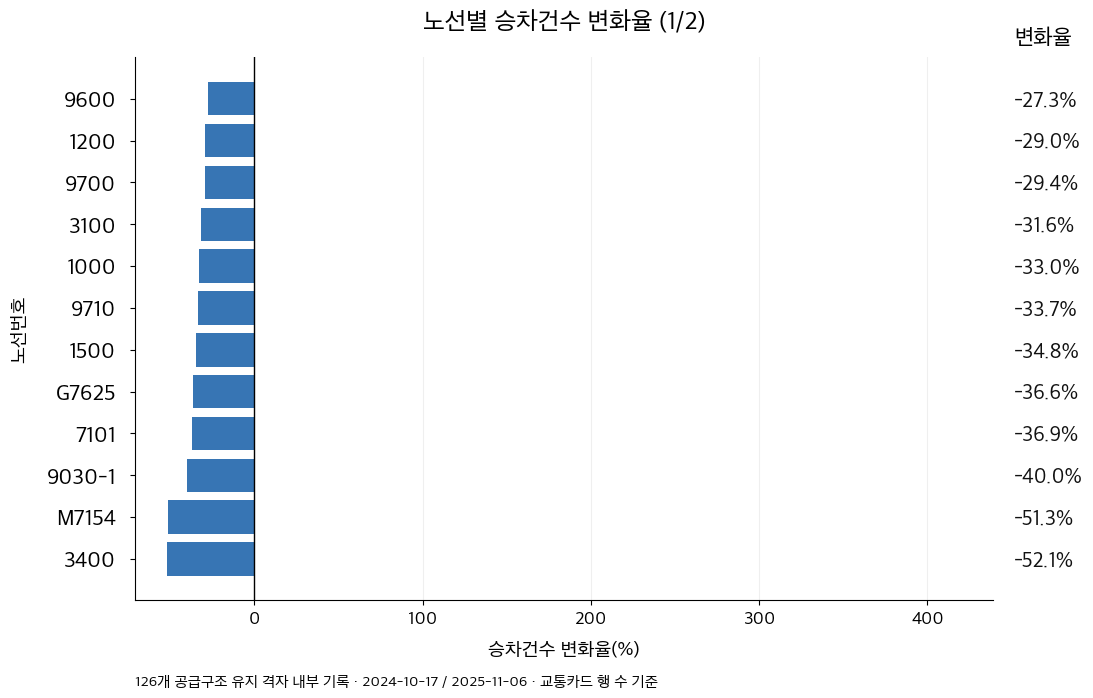

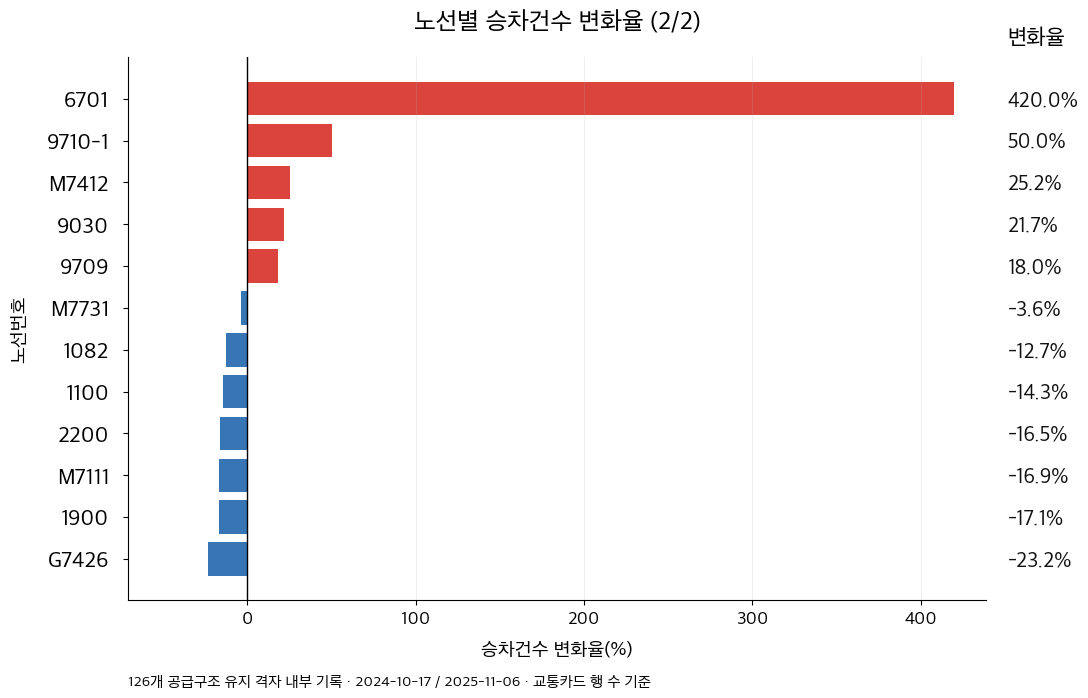

In [2]:
# 건수 기준 노선별 변화율: 기존 이용인원 기준 결과와 별도로 계산
from pathlib import Path
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
from IPython.display import display

count_root = next(p for p in [Path.cwd(), *Path.cwd().parents]
                  if (p / 'config.py').is_file() and (p / 'code').is_dir())
count_stable_path = count_root / 'data/processed/gtx_a/16_새데이터_공급구조유지_250m격자.csv'
count_reference_path = count_root / 'data/final/gtx_a/S1_126격자_건수기준_기초표.csv'
count_card_dir = count_root / 'data/raw/gtx_a/transport_card'
count_stable = pd.read_csv(count_stable_path, dtype=str, encoding='utf-8-sig')
count_reference = pd.read_csv(count_reference_path, encoding='utf-8-sig').set_index('셀 ID')
assert len(count_stable) == 126 and count_stable['셀 ID'].is_unique
assert set(count_stable['셀 ID'].astype(int)) == set(count_reference.index)

for count_font in [Path('/System/Library/Fonts/AppleSDGothicNeo.ttc'),
                   Path(r'C:\Windows\Fonts\malgun.ttf'),
                   Path('/Library/Fonts/NanumGothic.ttf')]:
    if count_font.is_file():
        fm.fontManager.addfont(str(count_font))
        plt.rcParams['font.family'] = fm.FontProperties(fname=str(count_font)).get_name()
        break
plt.rcParams['axes.unicode_minus'] = False

count_series = []
for count_year, count_filename in [
    (2024, 'gtx_a_transport_card_20241017_raw_with_coords_api_filled.csv'),
    (2025, 'gtx_a_transport_card_20251106_raw_with_coords.csv'),
]:
    count_card = pd.read_csv(count_card_dir / count_filename, dtype=str, encoding='utf-8-sig')
    count_expected_date = '20241017' if count_year == 2024 else '20251106'
    assert count_card['query_date'].eq(count_expected_date).all()
    count_lookup = pd.DataFrame([
        (int(row['셀 ID']), stop_id)
        for _, row in count_stable.iterrows()
        for stop_id in re.findall(r'\d{6,}', row[f'{count_year}년 정류장 ID'])
    ], columns=['셀 ID', '승차정류장ID'])
    assert not count_lookup['승차정류장ID'].duplicated().any(), '중복 정류장 매핑 확인 필요'
    count_selected = count_card.merge(count_lookup, on='승차정류장ID', how='inner', validate='many_to_one')
    count_selected['노선'] = count_selected['query_route_no'].str.strip().str.replace(r'\.0$', '', regex=True)
    assert count_selected['노선'].notna().all() and count_selected['노선'].ne('').all()
    count_by_cell = count_selected.groupby('셀 ID').size().reindex(count_reference.index, fill_value=0)
    np.testing.assert_array_equal(count_by_cell.to_numpy(), count_reference[f'board_{count_year}'].to_numpy())
    # utztn_nope 합계 대신 교통카드 행 수를 집계한다. 별도 중복 제거는 하지 않는다.
    count_series.append(count_selected.groupby('노선').size().rename(f'{count_year}년 승차건수'))

route_change_count = pd.concat(count_series, axis=1).fillna(0).astype(int).reset_index()
route_change_count['변화량(건)'] = route_change_count['2025년 승차건수'] - route_change_count['2024년 승차건수']
route_change_count['변화율(%)'] = 100 * route_change_count['변화량(건)'] / route_change_count['2024년 승차건수'].replace(0, np.nan)
route_change_count['소규모 기초건수 주의'] = np.where(route_change_count['2024년 승차건수'] < 20, '20건 미만', '')
route_change_count = route_change_count.sort_values('변화율(%)', kind='stable').reset_index(drop=True)
count_total24 = int(route_change_count['2024년 승차건수'].sum())
count_total25 = int(route_change_count['2025년 승차건수'].sum())
print(f'126개 격자 · {len(route_change_count)}개 노선 | 2024-10-17: {count_total24:,}건 → 2025-11-06: {count_total25:,}건')
print(f'전체 변화율: {(count_total25 / count_total24 - 1) * 100:.2f}% | 격자별 S1 건수와 일치 확인')
display(route_change_count.round(2))

count_finite = route_change_count['변화율(%)'].dropna()
count_padding = max(5.0, float(count_finite.max() - count_finite.min()) * 0.04)
count_mid = int(np.ceil(len(route_change_count) / 2))
for count_number, count_part in enumerate([route_change_count.iloc[:count_mid], route_change_count.iloc[count_mid:]], 1):
    fig, ax = plt.subplots(figsize=(13, max(7, len(count_part) * .62)))
    count_colors = np.where(count_part['변화율(%)'] < 0, '#2166ac', '#d73027')
    ax.barh(count_part['노선'], count_part['변화율(%)'], color=count_colors, alpha=.9)
    ax.axvline(0, color='black', linewidth=1)
    ax.set_xlim(float(count_finite.min()) - count_padding, float(count_finite.max()) + count_padding)
    ax.set_xlabel('승차건수 변화율(%)', fontsize=14, labelpad=10)
    ax.set_ylabel('노선번호', fontsize=14, labelpad=14)
    ax.set_title(f'노선별 승차건수 변화율 ({count_number}/2)', fontsize=18, fontweight='bold', pad=20)
    ax.spines[['top', 'right']].set_visible(False)
    ax.grid(axis='x', alpha=.2)
    ax.tick_params(axis='y', pad=10, labelsize=16)
    ax.tick_params(axis='x', labelsize=13)
    for count_label in ax.get_yticklabels():
        count_label.set_fontweight('bold')
    ax.text(1.025, 1.025, '변화율', transform=ax.transAxes, fontsize=16, fontweight='bold')
    for count_y, count_rate in enumerate(count_part['변화율(%)']):
        ax.text(1.025, count_y, f'{count_rate:.1f}%' if pd.notna(count_rate) else '산출 불가',
                transform=ax.get_yaxis_transform(), va='center', ha='left', fontsize=15, fontweight='bold', color='#111111', clip_on=False)
    fig.subplots_adjust(left=.16, right=.82, top=.87, bottom=.14)
    fig.text(.16, .025, '126개 공급구조 유지 격자 내부 기록 · 2024-10-17 / 2025-11-06 · 교통카드 행 수 기준', fontsize=11)
    plt.show()


## 6. 126개 격자의 2024년 건축물 연면적 지도

11-8 OLS 기본모형에서 유의하게 나타난 2024년 건축물 연면적(천㎡)의 공간분포를 공급구조 유지 126개 격자에 표시한다. 색이 진할수록 격자 안의 건축물 연면적이 크다. 연면적 분포가 오른쪽으로 치우쳐 있어 낮은 값의 공간 차이도 보이도록 제곱근 색상 정규화를 적용하였다. 녹색 별과 테두리는 GTX-A역 위치 및 역 포함 격자이다.

,건축물 연면적(천㎡)
count,126.000
mean,3.752
std,3.714
min,0.000
25%,0.595
50%,2.237
75%,6.364
90%,8.956
95%,10.983
max,14.575


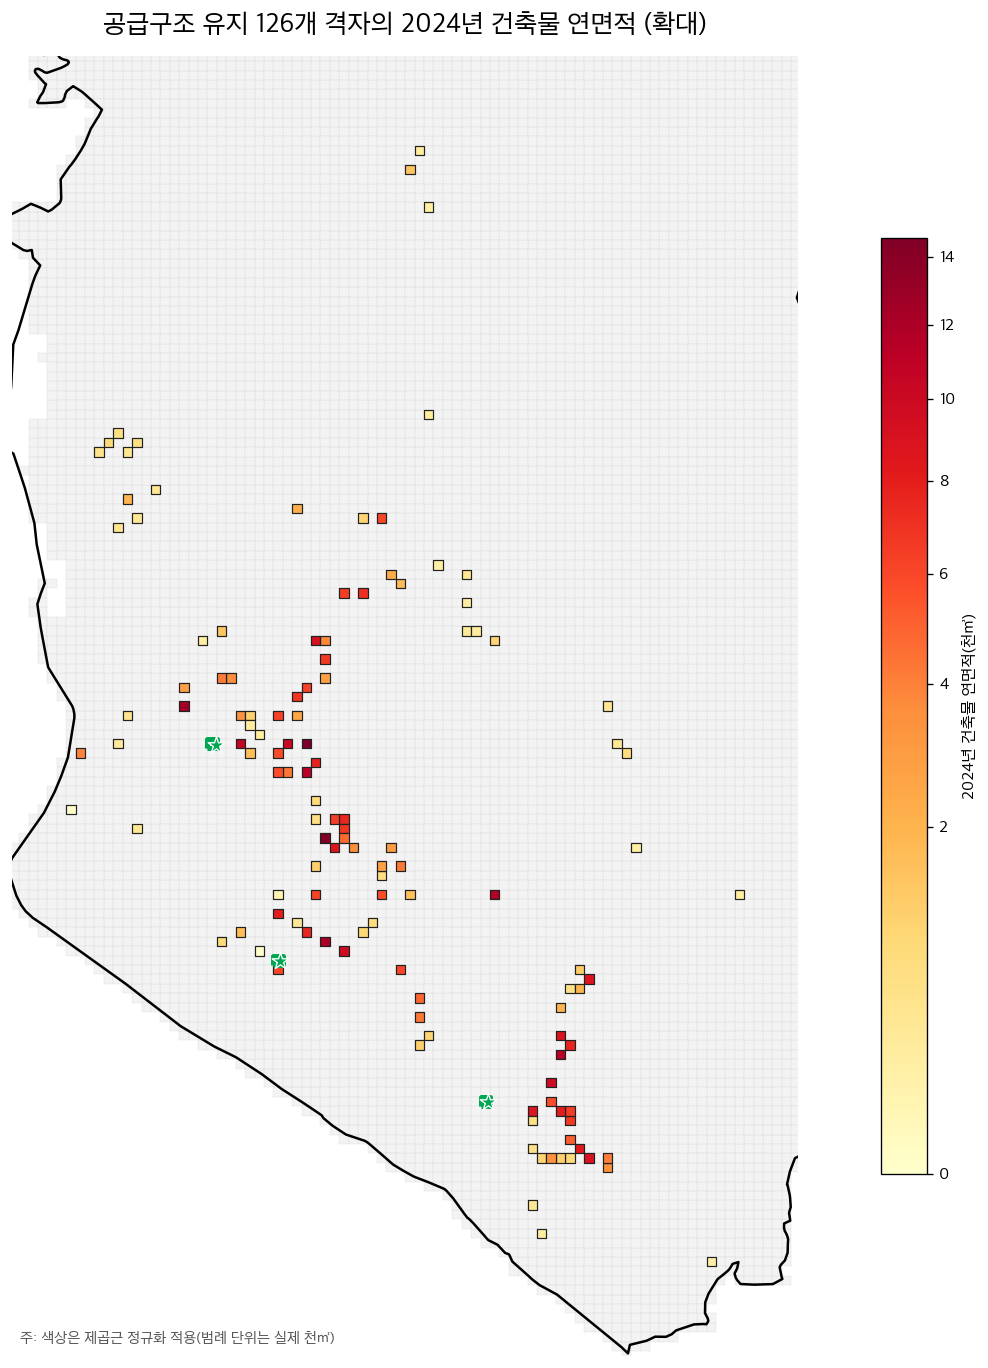

In [20]:
# 126개 분석 격자의 2024년 건축물 연면적 확대 지도
# 앞 셀의 지도 객체를 이용하며, 연면적 자료만 셀 ID로 추가 병합한다.
from matplotlib.colors import PowerNorm

FLOOR_PATH = PROCESSED / '24_건축물연면적_2024_250m격자.csv'
floor = pd.read_csv(FLOOR_PATH, encoding='utf-8-sig')
floor['셀 ID'] = pd.to_numeric(floor['셀 ID'], errors='coerce').astype('Int64')
floor_col = '2024년 건축물 연면적(천㎡)'

floor_grid = plot_grid[['셀 ID', 'geometry']].merge(
    floor[['셀 ID', floor_col]],
    on='셀 ID', how='left', validate='one_to_one'
)
assert len(floor_grid) == 126, f'분석 격자 수 오류: {len(floor_grid)}'
assert floor_grid[floor_col].notna().all(), '건축물 연면적 결측값이 있습니다.'

floor_summary = floor_grid[floor_col].describe(
    percentiles=[0.25, 0.5, 0.75, 0.9, 0.95]
).rename('건축물 연면적(천㎡)').to_frame()
display(floor_summary.round(3))

vmax = float(floor_grid[floor_col].max())
floor_norm = PowerNorm(gamma=0.5, vmin=0, vmax=vmax)

fig, ax = plt.subplots(figsize=(14, 11.5))
grid.plot(
    ax=ax, facecolor='#F3F3F3', edgecolor='#D0D0D0',
    linewidth=0.16, zorder=1
)
floor_grid.plot(
    ax=ax, column=floor_col, cmap='YlOrRd', norm=floor_norm,
    edgecolor='#222222', linewidth=0.72, legend=True,
    legend_kwds={'label': '2024년 건축물 연면적(천㎡)', 'shrink': 0.72},
    zorder=2
)
station_cells.boundary.plot(ax=ax, color='#00A651', linewidth=3.0, zorder=4)
stations.plot(
    ax=ax, color='#00A651', marker='*', markersize=110,
    edgecolor='white', linewidth=0.8, zorder=5
)
boundary_gdf.boundary.plot(ax=ax, color='black', linewidth=1.5, zorder=6)

xmin, ymin, xmax, ymax = floor_grid.total_bounds
padx, pady = (xmax-xmin)*0.08, (ymax-ymin)*0.08
ax.set_xlim(xmin-padx, xmax+padx)
ax.set_ylim(ymin-pady, ymax+pady)
ax.set_title('공급구조 유지 126개 격자의 2024년 건축물 연면적 (확대)', fontsize=16, pad=14)
ax.text(
    0.01, 0.01, '주: 색상은 제곱근 정규화 적용(범례 단위는 실제 천㎡)',
    transform=ax.transAxes, fontsize=9, color='#555555'
)
ax.set_axis_off()
plt.tight_layout()

plt.show()


## 부록. 로그변환 대상 변수의 원자료 분포

보행시간과 건축물 연면적의 로그변환 근거를 확인하기 위해 변환 전 원자료 분포를 각각 한 장으로 제시한다. X축은 변수의 실제 단위, Y축은 해당 구간에 포함된 250m 분석격자 수이다.


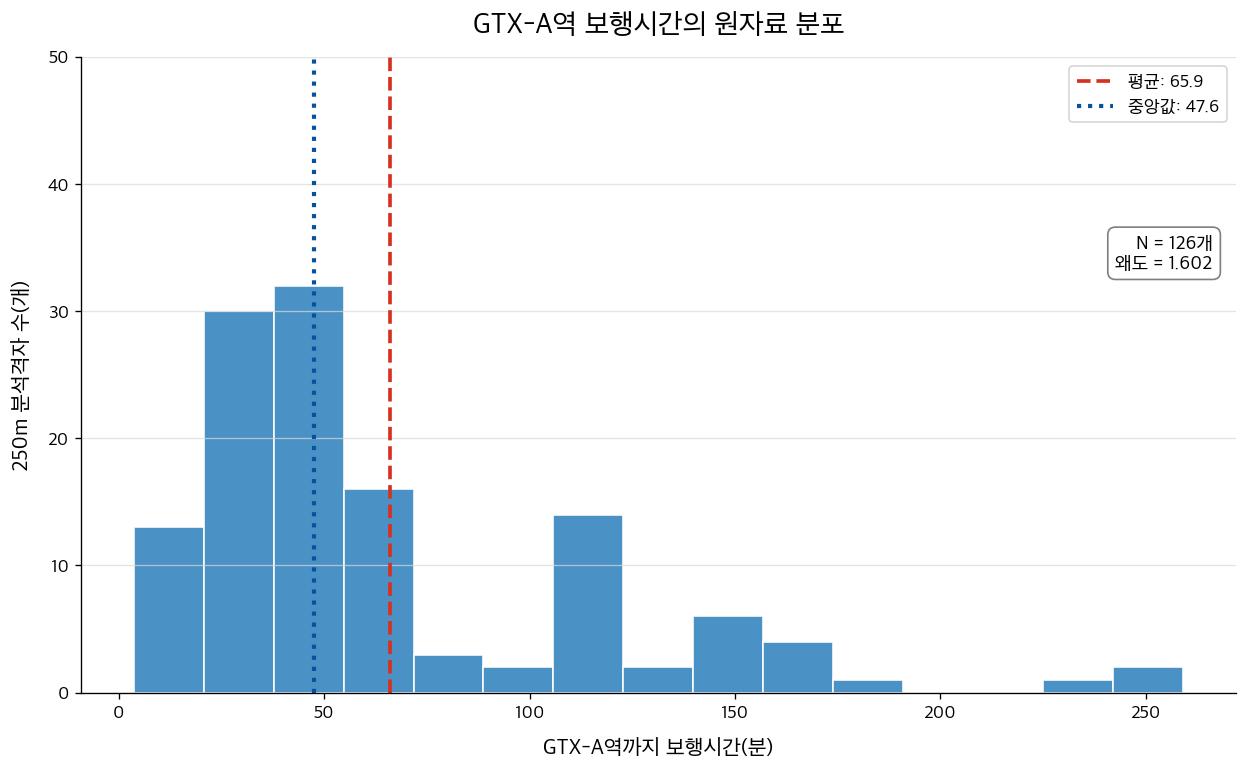

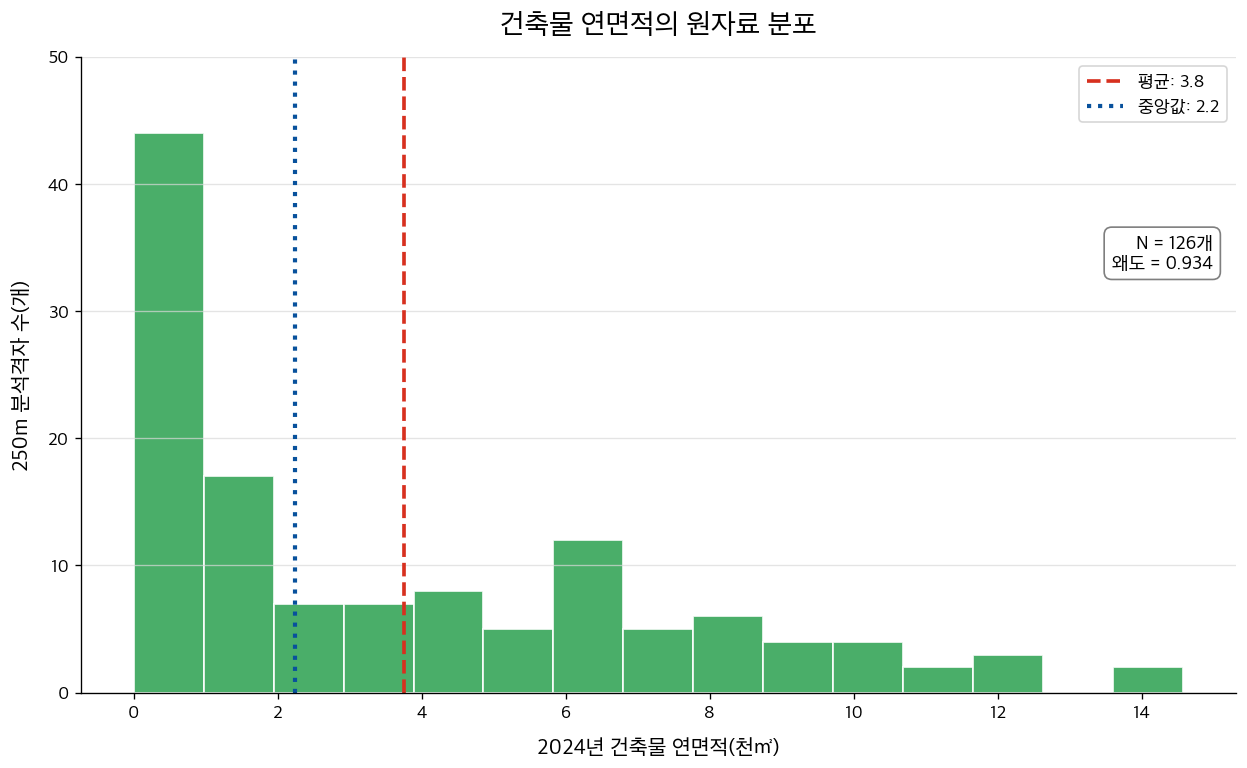

In [21]:
# 부록용 로그변환 대상 변수 원자료 분포: 변수별 한 장
from matplotlib.ticker import MaxNLocator


def plot_raw_distribution(values, xlabel, title, color, bins=15):
    values = pd.to_numeric(values, errors='coerce').dropna()
    mean_value = values.mean()
    median_value = values.median()
    skewness = values.skew()

    fig, ax = plt.subplots(figsize=(10.5, 6.5))
    ax.hist(
        values, bins=bins, color=color, edgecolor='white',
        linewidth=1.1, alpha=0.88,
    )
    ax.axvline(
        mean_value, color='#D7301F', linestyle='--', linewidth=2.2,
        label=f'평균: {mean_value:.1f}',
    )
    ax.axvline(
        median_value, color='#08519C', linestyle=':', linewidth=2.5,
        label=f'중앙값: {median_value:.1f}',
    )
    ax.set_title(title, fontsize=17, fontweight='bold', pad=14)
    ax.set_xlabel(xlabel, fontsize=13, labelpad=10)
    ax.set_ylabel('250m 분석격자 수(개)', fontsize=13, labelpad=10)
    ax.set_ylim(0, 50)
    ax.set_yticks(np.arange(0, 51, 10))
    ax.tick_params(axis='both', labelsize=11)
    ax.grid(axis='y', color='#D9D9D9', linewidth=0.8, alpha=0.7)
    ax.spines[['top', 'right']].set_visible(False)
    ax.legend(loc='upper right', frameon=True, fontsize=11)
    ax.text(
        0.98, 0.72,
        f'N = {len(values)}개\n왜도 = {skewness:.3f}',
        transform=ax.transAxes, ha='right', va='top', fontsize=11.5,
        bbox=dict(boxstyle='round,pad=0.4', facecolor='white',
                  edgecolor='#777777', alpha=0.94),
    )
    plt.tight_layout()
    plt.show()


plot_raw_distribution(
    model['walk_min'],
    xlabel='GTX-A역까지 보행시간(분)',
    title='GTX-A역 보행시간의 원자료 분포',
    color='#3182BD',
    bins=15,
)

plot_raw_distribution(
    floor[floor_col],
    xlabel='2024년 건축물 연면적(천㎡)',
    title='건축물 연면적의 원자료 분포',
    color='#31A354',
    bins=15,
)


## 7. A3 Ridge Logistic OOF 오차행렬

12-5의 중첩 Leave-One-Station-Out OOF 예측 결과를 전체 및 역 권역별 오차행렬로 표시한다. 분류 기준은 증가확률 0.5이며, 괄호 안 비율은 각 실제 집단 행 안에서의 비율이다.

,구분,표본 수,TN,FP,FN,TP,Accuracy,Balanced Accuracy,Sensitivity,Specificity
0,전체 OOF,126,26,34,17,49,0.595,0.588,0.742,0.433
1,대곡,37,4,15,2,16,0.541,0.550,0.889,0.211
2,운정중앙,63,11,18,4,30,0.651,0.631,0.882,0.379
3,킨텍스,26,11,1,11,3,0.538,0.565,0.214,0.917


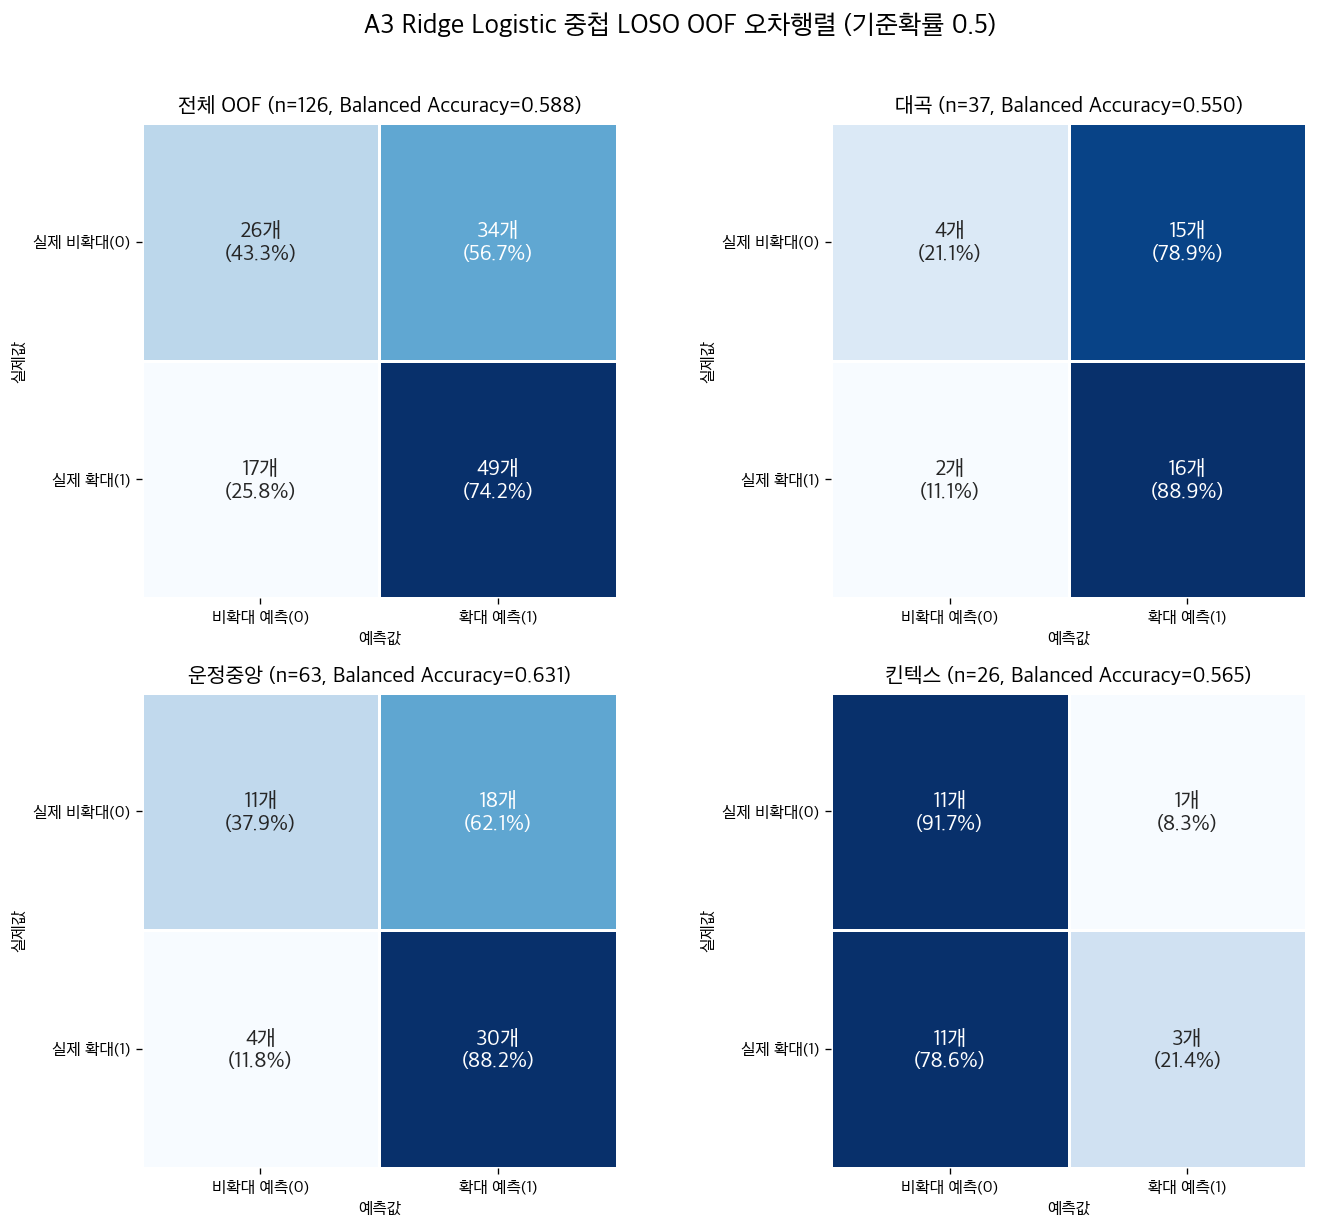

In [22]:
# A3 중첩 LOSO OOF 오차행렬 시각화
# 12-5에서 검증된 OOF 집계값을 사용한다.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

plt.rcParams['font.family'] = 'Apple SD Gothic Neo'
plt.rcParams['axes.unicode_minus'] = False

confusion_results = {
    '전체 OOF': np.array([[26, 34], [17, 49]]),
    '대곡': np.array([[4, 15], [2, 16]]),
    '운정중앙': np.array([[11, 18], [4, 30]]),
    '킨텍스': np.array([[11, 1], [11, 3]]),
}

def annotations(cm):
    row_total = cm.sum(axis=1, keepdims=True)
    row_pct = np.divide(cm, row_total, out=np.zeros_like(cm, dtype=float), where=row_total != 0) * 100
    return np.array([
        [f'{cm[i, j]}개\n({row_pct[i, j]:.1f}%)' for j in range(2)]
        for i in range(2)
    ])

def balanced_accuracy_from_cm(cm):
    specificity = cm[0, 0] / cm[0].sum()
    sensitivity = cm[1, 1] / cm[1].sum()
    return (specificity + sensitivity) / 2

fig, axes = plt.subplots(2, 2, figsize=(12, 10))
for ax, (name, cm) in zip(axes.flat, confusion_results.items()):
    sns.heatmap(
        cm, annot=annotations(cm), fmt='', cmap='Blues', cbar=False,
        linewidths=1.5, linecolor='white', square=True, ax=ax,
        xticklabels=['비확대 예측(0)', '확대 예측(1)'],
        yticklabels=['실제 비확대(0)', '실제 확대(1)'],
        annot_kws={'size': 13, 'weight': 'bold'},
    )
    n = int(cm.sum())
    balanced_accuracy = balanced_accuracy_from_cm(cm)
    ax.set_title(
        f'{name} (n={n}, Balanced Accuracy={balanced_accuracy:.3f})',
        fontsize=13, weight='bold'
    )
    ax.set_xlabel('예측값')
    ax.set_ylabel('실제값')
    ax.tick_params(axis='x', rotation=0)
    ax.tick_params(axis='y', rotation=0)

fig.suptitle(
    'A3 Ridge Logistic 중첩 LOSO OOF 오차행렬 (기준확률 0.5)',
    fontsize=16, weight='bold', y=1.02
)
plt.tight_layout()
plt.show()

metric_rows = []
for name, cm in confusion_results.items():
    tn, fp, fn, tp = cm.ravel()
    metric_rows.append({
        '구분': name, '표본 수': cm.sum(),
        'TN': tn, 'FP': fp, 'FN': fn, 'TP': tp,
        'Accuracy': (tn + tp) / cm.sum(),
        'Balanced Accuracy': balanced_accuracy_from_cm(cm),
        'Sensitivity': tp / (tp + fn),
        'Specificity': tn / (tn + fp),
    })
metrics = pd.DataFrame(metric_rows)
display(metrics.round(3))

### 해석

- 전체 OOF에서는 실제 확대 격자 66개 중 49개를 확대라고 맞혀 민감도가 높다.
- 실제 비확대 격자 60개 중 26개만 비확대로 맞혀 특이도는 상대적으로 낮다.
- 따라서 현재 모형은 확대 후보를 폭넓게 찾는 성향이 있으며, GTX-B·C에서는 0/1 확정 분류보다 예측점수의 상대적 순위를 중심으로 활용한다.
- ROC-AUC는 임계값 전체에서 순위 판별력을 평가하고, 이 오차행렬은 임계값 0.5에서의 최종 분류 결과를 보여준다.

## 8. 쌍대 비교 Ridge 순위모형 성능 시각화

같은 GTX역 권역에서 실제 수요 비중 확대 격자가 비확대 격자보다 높은 점수를 받도록 학습한 순위 전용 모형의 외부 검증 결과이다. 각 외부 검증에서 해당 역 권역을 학습과 규제강도 선택에서 완전히 제외한 중첩 Leave-One-Station-Out OOF 점수를 사용한다.

순위모형은 확대확률이나 0.5 분류기준을 사용하지 않으므로 오차행렬보다 다음 지표가 목적에 직접 대응한다.

- **ROC-AUC**: 실제 확대 격자를 비확대 격자보다 위에 배치하는 능력
- **Pairwise Log Loss**: 올바른 순서에 부여한 확신의 적절성. 낮을수록 좋으며 정보 없는 기준은 0.6931
- **Precision@K**: 예측점수 상위 K% 중 실제 확대 격자의 비율
- **Lift@K**: Precision@K를 해당 권역 전체 확대 비율로 나눈 값


,검증역,검증 격자 수,선택 C,ROC-AUC,Pairwise Log Loss,비교쌍 수
0,대곡,37,31.6228,0.6842,0.6085,342
1,운정중앙,63,0.1000,0.7769,0.5126,986
2,킨텍스,26,0.3162,0.7321,0.5477,168
3,요약,126,NaN,0.7311,0.5385,1496


,검증역,상위 구간,K,권역 실제 확대 비율,Precision@K,Lift
0,대곡,상위 10%,4,0.4865,0.5000,1.0278
1,대곡,상위 20%,8,0.4865,0.7500,1.5417
2,대곡,상위 30%,12,0.4865,0.7500,1.5417
3,운정중앙,상위 10%,7,0.5397,1.0000,1.8529
4,운정중앙,상위 20%,13,0.5397,0.8462,1.5679
5,운정중앙,상위 30%,19,0.5397,0.8421,1.5604
6,킨텍스,상위 10%,3,0.5385,0.6667,1.2381
7,킨텍스,상위 20%,6,0.5385,0.8333,1.5476
8,킨텍스,상위 30%,8,0.5385,0.7500,1.3929


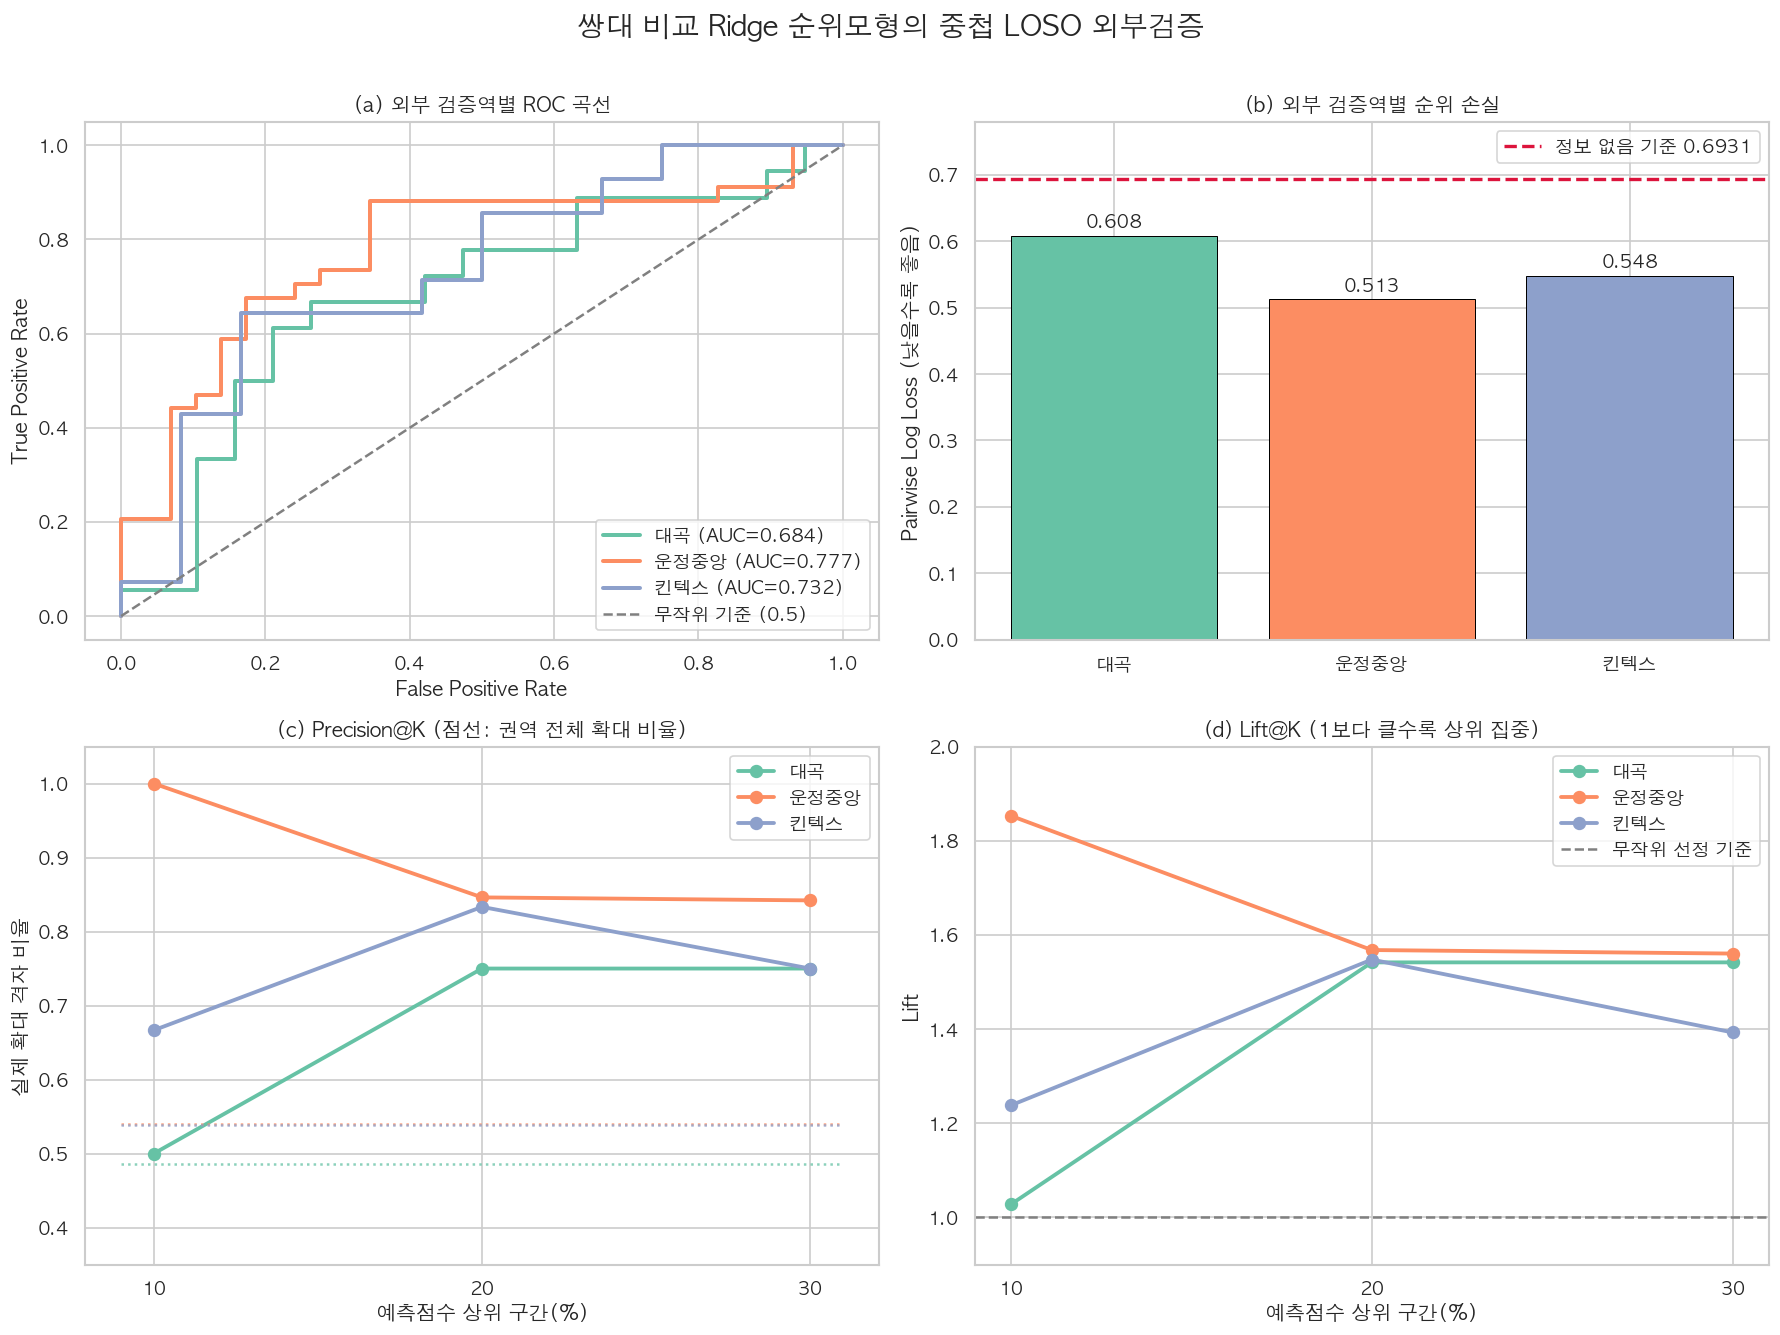

In [23]:
# 쌍대 비교 Ridge 순위모형: 중첩 LOSO 성능 시각화
from pathlib import Path
import importlib.util
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import seaborn as sns
from sklearn.metrics import roc_auc_score, roc_curve
from IPython.display import display

# 노트북을 저장소 루트 또는 analysis 폴더에서 실행하는 경우 모두 지원
_candidates = [
    *(UROP_ROOT / 'code').rglob('12-8_A3_쌍대비교_순위모형.py'),
    Path.cwd() / '12-8_A3_쌍대비교_순위모형.py',
    Path.cwd() / 'gtx_a_bus_analysis/analysis/12-8_A3_쌍대비교_순위모형.py',
]
RANK_SCRIPT = next((p for p in _candidates if p.exists()), None)
if RANK_SCRIPT is None:
    raise FileNotFoundError('12-8_A3_쌍대비교_순위모형.py를 찾을 수 없습니다.')

spec = importlib.util.spec_from_file_location('pairwise_rank_viz', RANK_SCRIPT)
rank = importlib.util.module_from_spec(spec)
spec.loader.exec_module(rank)
base = rank.load_base_module()
rank_data = base.load_data().dropna(
    subset=['nearest_station', 'share_increase', *rank.FEATURES]
).copy()
rank_data['share_increase'] = rank_data['share_increase'].astype(int)

oof_rows, fold_rows, top_rows = [], [], []
all_pair_losses = []
for test_station in rank_data['nearest_station'].astype(str).unique():
    train = rank_data[rank_data['nearest_station'].astype(str) != test_station]
    test = rank_data[rank_data['nearest_station'].astype(str) == test_station].copy()
    best_c, inner_auc = rank.choose_c_inner_loso(train)
    pair_x, pair_y = rank.make_pairs(train)
    fitted_ranker = rank.make_model(best_c).fit(pair_x, pair_y)
    test['ranking_score'] = rank.cell_scores(fitted_ranker, test)

    pair_loss, pair_count = rank.pairwise_log_loss(test, test['ranking_score'].to_numpy())
    pos = test.loc[test['share_increase'] == 1, 'ranking_score'].to_numpy()
    neg = test.loc[test['share_increase'] == 0, 'ranking_score'].to_numpy()
    all_pair_losses.append(np.logaddexp(0.0, -(pos[:, None] - neg[None, :]).ravel()))
    fold_rows.append({
        '검증역': test_station,
        '검증 격자 수': len(test),
        '선택 C': best_c,
        'ROC-AUC': roc_auc_score(test['share_increase'], test['ranking_score']),
        'Pairwise Log Loss': pair_loss,
        '비교쌍 수': pair_count,
    })
    top_rows.extend(rank.precision_lift_rows(test, test['ranking_score'].to_numpy()))
    oof_rows.append(test[['nearest_station', 'share_increase', 'ranking_score']])

rank_oof = pd.concat(oof_rows, ignore_index=True)
rank_fold = pd.DataFrame(fold_rows)
rank_top = pd.DataFrame(top_rows)
rank_top['상위 비율(%)'] = rank_top['상위 구간'].str.extract(r'(\d+)').astype(int)

# 한글 글꼴
for _font in ['AppleGothic', 'Malgun Gothic', 'NanumGothic']:
    if any(f.name == _font for f in fm.fontManager.ttflist):
        plt.rcParams['font.family'] = _font
        break
plt.rcParams['axes.unicode_minus'] = False
sns.set_theme(style='whitegrid', font=plt.rcParams.get('font.family', ['sans-serif'])[0])

station_order = rank_fold['검증역'].tolist()
colors = dict(zip(station_order, sns.color_palette('Set2', len(station_order))))
fig, axes = plt.subplots(2, 2, figsize=(15, 11))

# (a) 역별 ROC 곡선
ax = axes[0, 0]
for station in station_order:
    part = rank_oof[rank_oof['nearest_station'].astype(str) == station]
    fpr, tpr, _ = roc_curve(part['share_increase'], part['ranking_score'])
    auc = roc_auc_score(part['share_increase'], part['ranking_score'])
    ax.plot(fpr, tpr, lw=2.4, color=colors[station], label=f'{station} (AUC={auc:.3f})')
ax.plot([0, 1], [0, 1], '--', color='gray', lw=1.5, label='무작위 기준 (0.5)')
ax.set(xlabel='False Positive Rate', ylabel='True Positive Rate', title='(a) 외부 검증역별 ROC 곡선')
ax.legend(loc='lower right')

# (b) Pairwise Log Loss
ax = axes[0, 1]
bars = ax.bar(rank_fold['검증역'], rank_fold['Pairwise Log Loss'],
              color=[colors[s] for s in rank_fold['검증역']], edgecolor='black', linewidth=.6)
ax.axhline(np.log(2), color='crimson', linestyle='--', lw=2, label='정보 없음 기준 0.6931')
for bar, value in zip(bars, rank_fold['Pairwise Log Loss']):
    ax.text(bar.get_x() + bar.get_width()/2, value + .012, f'{value:.3f}', ha='center', fontsize=11)
ax.set_ylim(0, 0.78)
ax.set(ylabel='Pairwise Log Loss (낮을수록 좋음)', title='(b) 외부 검증역별 순위 손실')
ax.legend()

# (c) Precision@K
ax = axes[1, 0]
for station in station_order:
    part = rank_top[rank_top['검증역'].astype(str) == station].sort_values('상위 비율(%)')
    ax.plot(part['상위 비율(%)'], part['Precision@K'], marker='o', ms=7, lw=2.3,
            color=colors[station], label=station)
    baseline = part['권역 실제 확대 비율'].iloc[0]
    ax.hlines(baseline, 9, 31, colors=[colors[station]], linestyles=':', alpha=.75)
ax.set_xticks([10, 20, 30])
ax.set_ylim(0.35, 1.05)
ax.set(xlabel='예측점수 상위 구간(%)', ylabel='실제 확대 격자 비율', title='(c) Precision@K (점선: 권역 전체 확대 비율)')
ax.legend()

# (d) Lift@K
ax = axes[1, 1]
for station in station_order:
    part = rank_top[rank_top['검증역'].astype(str) == station].sort_values('상위 비율(%)')
    ax.plot(part['상위 비율(%)'], part['Lift'], marker='o', ms=7, lw=2.3,
            color=colors[station], label=station)
ax.axhline(1.0, color='gray', linestyle='--', lw=1.5, label='무작위 선정 기준')
ax.set_xticks([10, 20, 30])
ax.set_ylim(0.9, 2.0)
ax.set(xlabel='예측점수 상위 구간(%)', ylabel='Lift', title='(d) Lift@K (1보다 클수록 상위 집중)')
ax.legend()

fig.suptitle('쌍대 비교 Ridge 순위모형의 중첩 LOSO 외부검증', fontsize=17, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

rank_summary = rank_fold.copy()
rank_summary.loc[len(rank_summary)] = {
    '검증역': '요약',
    '검증 격자 수': rank_summary['검증 격자 수'].sum(),
    '선택 C': np.nan,
    'ROC-AUC': rank_summary['ROC-AUC'].mean(),
    'Pairwise Log Loss': np.concatenate(all_pair_losses).mean(),
    '비교쌍 수': rank_summary['비교쌍 수'].sum(),
}
display(rank_summary.round(4))
display(rank_top[['검증역', '상위 구간', 'K', '권역 실제 확대 비율', 'Precision@K', 'Lift']].round(4))


### 순위모형 결과 해석

- 역별 ROC-AUC는 대곡 0.684, 운정중앙 0.777, 킨텍스 0.732이며 단순평균은 0.731이다. 세 권역 모두 무작위 순위 기준인 0.5보다 높다.
- 전체 외부 비교쌍의 Pairwise Log Loss는 0.539로, 모든 쌍에 50%를 부여하는 정보 없는 기준 0.693보다 낮다.
- 상위 20% Precision은 대곡 75.0%, 운정중앙 84.6%, 킨텍스 83.3%이다.
- 상위 20% Lift는 세 역에서 1.54~1.57로 나타나, 예측점수 상위 격자에 실제 비중 확대 격자가 권역 전체보다 일관되게 집중되었다.
- 따라서 GTX-C에서는 확대·비확대를 확정 판정하거나 점수를 실제 확률로 해석하지 않고, 각 역 권역 안에서 상위 10%·20%·30% 우선검토 격자를 제시한다.
- 독립된 검증 권역이 세 곳뿐이므로 결과는 탐색적 순위 성능으로 해석한다.
